# 524H0158 - PHẦN I: THU THẬP, LÀM SẠCH VÀ TIỀN XỬ LÝ DỮ LIỆU

Dataset: **Students Performance in Exams** (Kaggle) - học sinh với 5 cột phân loại và 3 cột điểm (math, reading, writing).

Chạy file này **đầu tiên**: cuối file lưu `students_cleaned.csv` cho Phần II.

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# ---------- settings ----------
# use the shared folder if it exists, otherwise the current folder
FILE_PATH = "../shared/StudentsPerformance.csv" if os.path.exists("../shared/StudentsPerformance.csv") else "StudentsPerformance.csv"
CHART_FOLDER = "charts"            # folder for the charts of Part III
os.makedirs(CHART_FOLDER, exist_ok=True)

TARGET = "math score"                      # the score we want to explain
GROUP_COL = "race/ethnicity"               # the main group column
NAME_COL = "parental level of education"   # no student id in this file, so regex is used on this text column

## 1.1 Thu thập và tải dữ liệu

#### Đọc dữ liệu bằng Pandas vào DataFrame.

In [2]:
df = pd.read_csv(FILE_PATH)
print("Loaded:", FILE_PATH)

Loaded: ../shared/StudentsPerformance.csv


## 1.2 Khám phá và cấu trúc cơ bản

#### Hiển thị 5 dòng đầu, 5 dòng cuối, kích thước, kiểu dữ liệu và tổng quan.

In [3]:
print(df.head())                 # first 5 rows
print(df.tail())                 # last 5 rows
print("\nShape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
df.info()                        # short overview

# split the columns by type, so the names are not typed by hand
number_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude="number").columns.tolist()
print("\nNumber columns:", number_cols)
print("Text columns:", text_cols)

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
     gender race/ethnicity parental level of education         lunch  \
995  female        group E             master's degree      standard   
996    male    

## 1.3 Kiểm tra và làm sạch dữ liệu thật

#### Kiểm tra dữ liệu thiếu và dòng trùng, rồi làm sạch.

In [4]:
raw_shape = df.shape
n_missing_real = int(df.isnull().sum().sum())     # missing values in the real data
n_duplicates = int(df.duplicated().sum())         # duplicated rows in the real data
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicated rows:", n_duplicates)

# clean: keep the first copy of each duplicated row, drop rows with missing values (if any)
df = df.drop_duplicates().dropna().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

display(Markdown(
    f"**Nhận xét:** Dữ liệu thật gồm {raw_shape[0]} dòng, {raw_shape[1]} cột "
    f"({len(text_cols)} cột phân loại, {len(number_cols)} cột điểm), có {n_missing_real} giá trị thiếu "
    f"và {n_duplicates} dòng trùng. Sau khi làm sạch còn {len(df)} dòng ({raw_shape[0] - len(df)} dòng bị loại)."
))

Missing values per column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Duplicated rows: 0
Shape after cleaning: (1000, 8)


**Nhận xét:** Dữ liệu thật gồm 1000 dòng, 8 cột (5 cột phân loại, 3 cột điểm), có 0 giá trị thiếu và 0 dòng trùng. Sau khi làm sạch còn 1000 dòng (0 dòng bị loại).

## 1.4 Giả lập 5% dữ liệu thiếu và so sánh hai cách xử lý

#### Giả lập 5% thiếu ngẫu nhiên ở một cột điểm, rồi so sánh `fillna` (trung bình) với `dropna`.

In [5]:
# work on a copy, so the real data stays safe
df_dirty = df.copy()

# the column to break: the last number column that is not the target
miss_col = [c for c in number_cols if c != TARGET][-1]

# blank 5% of the rows of that column at random
miss_index = df_dirty.sample(frac=0.05, random_state=42).index
df_dirty.loc[miss_index, miss_col] = np.nan
print("Simulated 5% missing in:", miss_col)
print("\nMissing values per column:")
print(df_dirty.isnull().sum())

# method 1: fill with the mean of the column | method 2: drop the rows with missing values
df_filled = df_dirty.fillna({miss_col: df_dirty[miss_col].mean()})
df_dropped = df_dirty.dropna()
lost_pct = (1 - len(df_dropped) / len(df_dirty)) * 100
print("\nOriginal shape:", df.shape)
print("After fillna (mean):", df_filled.shape)
print("After dropna:", df_dropped.shape, "-> lost", round(lost_pct, 1), "% of the rows")

std_before, std_after = df[miss_col].std(), df_filled[miss_col].std()
std_word = "giảm" if std_after < std_before else ("tăng" if std_after > std_before else "không đổi")
display(Markdown(
    f"**Nhận xét:** Đã giả lập {int(df_dirty[miss_col].isnull().sum())} giá trị thiếu "
    f"({df_dirty[miss_col].isnull().mean() * 100:.1f}%) ở `{miss_col}`. "
    f"`fillna` (trung bình) giữ {len(df_filled)} dòng, còn `dropna` còn {len(df_dropped)} dòng, mất {lost_pct:.1f}% số dòng. "
    f"Độ lệch chuẩn của `{miss_col}` {std_word} từ {std_before:.2f} xuống {std_after:.2f} sau khi `fillna`"
    + (", vì các giá trị điền bằng trung bình không làm tăng độ phân tán. " if std_word == "giảm" else ". ")
    + "Các phần sau dùng dữ liệu thật đã làm sạch `df`, không dùng bản sao bị phá."
))

Simulated 5% missing in: writing score

Missing values per column:
gender                          0
race/ethnicity                  0
parental level of education     0
lunch                           0
test preparation course         0
math score                      0
reading score                   0
writing score                  50
dtype: int64

Original shape: (1000, 8)
After fillna (mean): (1000, 8)
After dropna: (950, 8) -> lost 5.0 % of the rows


**Nhận xét:** Đã giả lập 50 giá trị thiếu (5.0%) ở `writing score`. `fillna` (trung bình) giữ 1000 dòng, còn `dropna` còn 950 dòng, mất 5.0% số dòng. Độ lệch chuẩn của `writing score` giảm từ 15.20 xuống 14.72 sau khi `fillna`, vì các giá trị điền bằng trung bình không làm tăng độ phân tán. Các phần sau dùng dữ liệu thật đã làm sạch `df`, không dùng bản sao bị phá.

## 1.5 Cấu trúc Python cơ bản và Regex

In [6]:
# ---------- Series -> List -> filter with basic Python ----------
score_series = df[TARGET]                  # a pandas Series
score_list = score_series.tolist()         # the same values as a Python list

# keep only the values bigger than the average, using a plain loop
average = sum(score_list) / len(score_list)
above_average = []
for value in score_list:
    if value > average:
        above_average.append(value)
print("Values in the list:", len(score_list), "| average:", round(average, 3))
print("Values above the average:", len(above_average))

# show the first 10 filtered values to prove the filter worked
print("First 10 values above the average:", above_average[:10])

Values in the list: 1000 | average: 66.089
Values above the average: 493
First 10 values above the average: [72, 69, 90, 76, 71, 88, 78, 69, 88, 69]


In [7]:
# ---------- regular expressions (re) ----------
# 1) clean the column names: keep letters, digits and underscore only
def clean_name(name):
    return re.sub(r"\W+", "_", str(name).strip()).strip("_").lower()

print("Old names:", df.columns.tolist())
df = df.rename(columns={c: clean_name(c) for c in df.columns})
print("New names:", df.columns.tolist())

# the main columns and the column lists must follow the new names
TARGET, GROUP_COL, NAME_COL = clean_name(TARGET), clean_name(GROUP_COL), clean_name(NAME_COL)
number_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude="number").columns.tolist()

# 2) check the format of the NAME_COL values: only the allowed education levels
pattern = r"(some )?(high school|college)|(associate's|bachelor's|master's) degree"
is_valid = df[NAME_COL].apply(lambda s: re.fullmatch(pattern, s) is not None)
print("\nValid values in", NAME_COL + ":", is_valid.sum(), "| invalid:", (~is_valid).sum())

# 3) extract information: the degree type, for example "bachelor's degree" -> "bachelor"
degree_type = df[NAME_COL].str.extract(r"(\w+)'s degree")[0]
print("\nValues that contain a degree:", degree_type.notna().sum())
print(degree_type.value_counts())

Old names: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']
New names: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']

Valid values in parental_level_of_education: 1000 | invalid: 0

Values that contain a degree: 399
0
associate    222
bachelor     118
master        59
Name: count, dtype: int64


In [8]:
# ---------- save the cleaned real data for Part II -----------
out_path = "../shared/students_cleaned.csv" if os.path.exists("../shared/") else "students_cleaned.csv"
df.to_csv(out_path, index=False)
print("Saved:", out_path, "| shape:", df.shape)
print("Columns:", df.columns.tolist())

Saved: ../shared/students_cleaned.csv | shape: (1000, 8)
Columns: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


# PHẦN II: PHÂN TÍCH VÀ BIẾN ĐỔI DỮ LIỆU CHUYÊN SÂU

Dataset: **Students Performance in Exams** (Kaggle) - học sinh với 5 cột phân loại và 3 cột điểm (math, reading, writing).

Chạy file này **sau Phần I**: đọc `students_cleaned.csv` (đã loại dòng trùng/thiếu và đổi tên cột về dạng `snake_case`), cuối file lưu `students_part2.csv` cho Phần III.

In [9]:
# Import pandas để làm việc với dữ liệu dạng bảng (DataFrame)
import pandas as pd
# Import numpy để tạo cột theo điều kiện (np.where)
import numpy as np
# Import os để kiểm tra thư mục shared có tồn tại hay không
import os

# ---------- settings (giống Phần I) ----------
# Đọc file đã làm sạch do Phần I lưu: ưu tiên thư mục shared, nếu không có thì dùng thư mục hiện tại
DUONG_DAN = "../shared/students_cleaned.csv" if os.path.exists("../shared/students_cleaned.csv") else "students_cleaned.csv"
TARGET = "math_score"          # cột điểm cần phân tích
GROUP_COL = "race_ethnicity"   # cột nhóm chính

# Đọc dữ liệu đã làm sạch (Phần I đã kiểm tra thiếu/trùng và đổi tên cột nên không làm lại ở đây)
df = pd.read_csv(DUONG_DAN)
print("Đã đọc:", DUONG_DAN, "| kích thước:", df.shape)
print("Các cột:", df.columns.tolist())

# Các cột điểm: lấy từ cột số, tính TRƯỚC khi thêm cột mới để chỉ gồm 3 cột điểm gốc
number_cols = df.select_dtypes(include="number").columns.tolist()
CAC_DIEM = number_cols
print("Các cột điểm:", CAC_DIEM)

Đã đọc: ../shared/students_cleaned.csv | kích thước: (1000, 8)
Các cột: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']
Các cột điểm: ['math_score', 'reading_score', 'writing_score']


## 2.1 Kỹ thuật Indexing và Lọc (Indexing and Filtering)

#### Dùng `.loc[]`, `.iloc[]` để truy cập dữ liệu, rồi lọc bằng Boolean Indexing trên 2 cột.

### 2.1.1 Truy cập dữ liệu bằng `.loc[]` và `.iloc[]`

In [10]:
# ---------- .loc[]: truy cập theo NHÃN (tên dòng, tên cột) ----------
# Lấy 10 dòng đầu tiên (nhãn 0 đến 9; .loc bao gồm cả nhãn cuối nên 0:9 cho đúng 10 dòng) và 4 cột chỉ định theo tên
print("===== .loc[]: 10 dòng đầu, 4 cột chọn theo tên =====")
print(df.loc[0:9, ["gender", "math_score", "reading_score", "writing_score"]])

# ---------- .iloc[]: truy cập theo VỊ TRÍ (số thứ tự dòng, số thứ tự cột) ----------
# Lấy 10 dòng đầu (vị trí 0 đến 9; .iloc KHÔNG bao gồm vị trí cuối nên :10 cho đúng 10 dòng)
# và các cột ở vị trí 0, 5, 6, 7 (tương ứng gender, math_score, reading_score, writing_score)
print("\n===== .iloc[]: 10 dòng đầu, các cột ở vị trí 0, 5, 6, 7 =====")
print(df.iloc[:10, [0, 5, 6, 7]])

# Kiểm tra lại tên của các cột ở vị trí 0, 5, 6, 7 để chắc chắn chọn đúng
print("\nTên các cột ở vị trí 0, 5, 6, 7:", df.columns[[0, 5, 6, 7]].tolist())

===== .loc[]: 10 dòng đầu, 4 cột chọn theo tên =====
   gender  math_score  reading_score  writing_score
0  female          72             72             74
1  female          69             90             88
2  female          90             95             93
3    male          47             57             44
4    male          76             78             75
5  female          71             83             78
6  female          88             95             92
7    male          40             43             39
8    male          64             64             67
9  female          38             60             50

===== .iloc[]: 10 dòng đầu, các cột ở vị trí 0, 5, 6, 7 =====
   gender  math_score  reading_score  writing_score
0  female          72             72             74
1  female          69             90             88
2  female          90             95             93
3    male          47             57             44
4    male          76             78             75


**Nhận xét:**
- `.loc[0:9, [...]]` chọn theo **nhãn** nên lấy cả nhãn 9 (đủ 10 dòng), còn `.iloc[:10, [...]]` chọn theo **vị trí** nên dừng trước vị trí 10 (cũng đủ 10 dòng). Do chỉ số của bảng là 0, 1, 2, ... liên tục nên hai cách cho cùng kết quả.
- Dùng `.loc` khi biết **tên** dòng/cột (dễ đọc, không sai khi thứ tự cột thay đổi); dùng `.iloc` khi chỉ biết **vị trí**. Ở ví dụ trên, `.iloc` phải đối chiếu lại tên cột ở vị trí 0, 5, 6, 7 (gender, math_score, reading_score, writing_score) để chắc chắn chọn đúng.

### 2.1.2 Lọc dữ liệu theo điều kiện trên 2 cột (Boolean Indexing)

In [11]:
# ---------- Ví dụ 1: học sinh có điểm toán >= 80 VÀ điểm đọc >= 80 ----------
# Mỗi điều kiện phải đặt trong ngoặc tròn; dùng & cho "và", | cho "hoặc", ~ cho "phủ định"
dieu_kien_1 = (df["math_score"] >= 80) & (df["reading_score"] >= 80)
# Lấy các dòng thoả điều kiện bằng cách đưa dãy True/False vào df[...]
nhom_gioi = df[dieu_kien_1]
# In số học sinh thoả điều kiện và tỷ lệ phần trăm so với toàn bộ dữ liệu
print("Điểm toán >= 80 và điểm đọc >= 80:", len(nhom_gioi), "học sinh (", round(len(nhom_gioi) / len(df) * 100, 1), "% )")
# In 5 dòng đầu của nhóm
print(nhom_gioi.head())

# ---------- Ví dụ 2: học sinh ăn trưa miễn/giảm (free/reduced) VÀ điểm toán < 50 ----------
dieu_kien_2 = (df["lunch"] == "free/reduced") & (df["math_score"] < 50)
nhom_yeu = df[dieu_kien_2]
# In số học sinh thoả điều kiện
print("\nlunch = free/reduced và điểm toán < 50:", len(nhom_yeu), "học sinh")
# So sánh với toàn bộ học sinh có điểm toán < 50: trong đó bao nhiêu thuộc nhóm free/reduced (value_counts đếm số lần xuất hiện)
print("\nCác học sinh có điểm toán < 50 chia theo lunch:")
print(df[df["math_score"] < 50]["lunch"].value_counts())

Điểm toán >= 80 và điểm đọc >= 80: 143 học sinh ( 14.3 % )
    gender race_ethnicity parental_level_of_education     lunch  \
2   female        group B             master's degree  standard   
6   female        group B                some college  standard   
16    male        group C                 high school  standard   
34    male        group E                some college  standard   
35    male        group E          associate's degree  standard   

   test_preparation_course  math_score  reading_score  writing_score  
2                     none          90             95             93  
6                completed          88             95             92  
16                    none          88             89             86  
34                    none          97             87             82  
35               completed          81             81             79  

lunch = free/reduced và điểm toán < 50: 96 học sinh

Các học sinh có điểm toán < 50 chia theo lunch:
lunch
free

**Nhận xét:**
- Có **143 học sinh (14,3%)** đạt từ 80 điểm trở lên ở cả toán và đọc.
- Có **96 học sinh** vừa ăn trưa miễn/giảm (`free/reduced`) vừa dưới 50 điểm toán. Trong tổng số 135 học sinh dưới 50 điểm toán, nhóm `free/reduced` chiếm khoảng **71%**, trong khi nhóm này chỉ chiếm 35,5% toàn bộ mẫu (355/1.000). Như vậy học sinh `free/reduced` xuất hiện nhiều bất thường trong nhóm điểm toán thấp.

## 2.2 Kỹ thuật Feature Engineering (Tạo thuộc tính mới)

#### Tạo ít nhất ba cột mới từ các cột có sẵn và chèn vào vị trí hợp lý bằng `.insert()`.

Tạo 4 cột mới như sau:

| Cột mới | Tạo từ | Ý nghĩa |
|---|---|---|
| `tong_diem` | 3 cột điểm | Tổng điểm 3 môn (tối đa 300) |
| `diem_trung_binh` | 3 cột điểm | Điểm trung bình 3 môn |
| `xep_loai` | `diem_trung_binh` | Xếp loại: Yếu (< 50), Trung bình (50 đến < 65), Khá (65 đến < 80), Giỏi (≥ 80) |
| `ket_qua` | 3 cột điểm | "Đạt" nếu cả 3 môn đều ≥ 50, ngược lại "Không đạt" |

In [12]:
# .insert(vị_trí, tên_cột, giá_trị) chèn cột mới vào đúng vị trí; vị trí lấy bằng df.columns.get_loc(tên cột)
# Vị trí ngay sau cột điểm cuối cùng (writing_score)
vi_tri = df.columns.get_loc("writing_score") + 1

# ---------- Cột 1: tong_diem, chèn ngay sau writing_score ----------
# sum(axis=1) cộng theo HÀNG, tức cộng 3 điểm của từng học sinh
df.insert(vi_tri, "tong_diem", df[CAC_DIEM].sum(axis=1))

# ---------- Cột 2: diem_trung_binh, chèn ngay sau tong_diem ----------
# mean(axis=1) lấy trung bình theo HÀNG; round(2) làm tròn 2 chữ số
df.insert(vi_tri + 1, "diem_trung_binh", df[CAC_DIEM].mean(axis=1).round(2))

# ---------- Cột 3: xep_loai, chèn ngay sau diem_trung_binh ----------
# pd.cut chia một cột số thành các khoảng; bins là các mốc chia, labels là tên của từng khoảng
# right=False nghĩa là khoảng đóng bên trái, mở bên phải: [0; 50), [50; 65), [65; 80), [80; 101)
df.insert(vi_tri + 2, "xep_loai",
          pd.cut(df["diem_trung_binh"], bins=[0, 50, 65, 80, 101], labels=["Yếu", "Trung bình", "Khá", "Giỏi"], right=False))

# ---------- Cột 4: ket_qua, chèn ở cuối bảng ----------
# (df[CAC_DIEM] >= 50).all(axis=1) là True khi CẢ 3 môn đều từ 50 điểm trở lên
# np.where(điều kiện, giá trị nếu đúng, giá trị nếu sai)
df.insert(len(df.columns), "ket_qua", np.where((df[CAC_DIEM] >= 50).all(axis=1), "Đạt", "Không đạt"))

# In các cột hiện có để thấy vị trí các cột mới
print("Các cột sau khi thêm:", df.columns.tolist())
# In 5 dòng đầu của các cột liên quan
print(df[CAC_DIEM + ["tong_diem", "diem_trung_binh", "xep_loai", "ket_qua"]].head())

# Đếm số lượng ở từng nhóm của hai cột phân loại mới để kiểm tra việc phân nhóm có hợp lý không
for cot in ["xep_loai", "ket_qua"]:
    print("\n--- " + cot + " ---")
    print(df[cot].value_counts().sort_index())

Các cột sau khi thêm: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'tong_diem', 'diem_trung_binh', 'xep_loai', 'ket_qua']
   math_score  reading_score  writing_score  tong_diem  diem_trung_binh  \
0          72             72             74        218            72.67   
1          69             90             88        247            82.33   
2          90             95             93        278            92.67   
3          47             57             44        148            49.33   
4          76             78             75        229            76.33   

  xep_loai    ket_qua  
0      Khá        Đạt  
1     Giỏi        Đạt  
2     Giỏi        Đạt  
3      Yếu  Không đạt  
4      Khá        Đạt  

--- xep_loai ---
xep_loai
Yếu           103
Trung bình    296
Khá           403
Giỏi          198
Name: count, dtype: int64

--- ket_qua ---
ket_qua
Không đạt    188
Đạt          812


**Nhận xét:**
- Các cột mới nằm đúng vị trí mong muốn: `tong_diem`, `diem_trung_binh`, `xep_loai` nằm liền sau `writing_score`, còn `ket_qua` ở cuối bảng.
- Phân bố xếp loại: Khá nhiều nhất (403), sau đó Trung bình (296), Giỏi (198) và Yếu (103).
- Có **812 học sinh Đạt (81,2%)** và 188 học sinh Không đạt (18,8%), tức cứ khoảng 5 học sinh thì có 1 em dưới 50 điểm ở ít nhất một môn.

## 2.3 Phân tích Thống kê và Nhóm (Statistical Analysis and Grouping)

#### Tính ma trận tương quan, thống kê theo nhóm và phân tích tác động của một biến lên biến khác.

### 2.3.1 Ma trận tương quan (`.corr()`)

In [13]:
# .corr() chỉ tính được trên cột số, nên mã hoá 3 cột chữ có 2 giá trị thành 0/1 trước
# chuan_bi_num: 1 nếu đã hoàn thành khoá luyện thi (completed), 0 nếu chưa (none)
df["chuan_bi_num"] = (df["test_preparation_course"] == "completed").astype(int)
# lunch_num: 1 nếu ăn trưa tiêu chuẩn (standard), 0 nếu miễn/giảm (free/reduced)
df["lunch_num"] = (df["lunch"] == "standard").astype(int)
# nam_num: 1 nếu là nam, 0 nếu là nữ
df["nam_num"] = (df["gender"] == "male").astype(int)

# Danh sách các biến đưa vào ma trận tương quan
CAC_BIEN = CAC_DIEM + ["chuan_bi_num", "lunch_num", "nam_num"]

# Tính ma trận tương quan Pearson giữa tất cả các biến
ma_tran = df[CAC_BIEN].corr()
# In ma trận, làm tròn 3 chữ số thập phân
print(ma_tran.round(3))

# Chỉ lấy tương quan giữa 3 biến mã hoá (hàng) và 3 điểm số (cột) để thấy yếu tố nào liên quan đến điểm
print("\nTương quan giữa các yếu tố và điểm số:")
print(ma_tran.loc[["chuan_bi_num", "lunch_num", "nam_num"], CAC_DIEM].round(3))

               math_score  reading_score  writing_score  chuan_bi_num  \
math_score          1.000          0.818          0.803         0.178   
reading_score       0.818          1.000          0.955         0.242   
writing_score       0.803          0.955          1.000         0.313   
chuan_bi_num        0.178          0.242          0.313         1.000   
lunch_num           0.351          0.230          0.246        -0.017   
nam_num             0.168         -0.244         -0.301         0.006   

               lunch_num  nam_num  
math_score         0.351    0.168  
reading_score      0.230   -0.244  
writing_score      0.246   -0.301  
chuan_bi_num      -0.017    0.006  
lunch_num          1.000    0.021  
nam_num            0.021    1.000  

Tương quan giữa các yếu tố và điểm số:
              math_score  reading_score  writing_score
chuan_bi_num       0.178          0.242          0.313
lunch_num          0.351          0.230          0.246
nam_num            0.168       

**Nhận xét:**
- Ba môn tương quan dương mạnh với nhau: **reading và writing 0,955** (rất mạnh), math với reading 0,818 và math với writing 0,803. Học sinh giỏi một môn thường giỏi các môn còn lại, đặc biệt là hai môn ngôn ngữ.
- `lunch_num` tương quan mạnh nhất với **toán** (0,351); `chuan_bi_num` (hoàn thành khoá luyện thi) tương quan mạnh nhất với **writing** (0,313).
- `nam_num` có dấu khác nhau giữa các môn: **dương với toán (+0,168)** nhưng **âm với reading (−0,244) và writing (−0,301)**, nghĩa là nam nhỉnh hơn ở toán còn nữ nhỉnh hơn ở đọc và viết.
- Các hệ số của biến 0/1 chỉ ở mức yếu đến trung bình, và tương quan không đồng nghĩa với nhân quả.

### 2.3.2 Nhóm theo cột cụ thể và tính thống kê mô tả (trung bình, độ lệch chuẩn, min, max)

In [14]:
# ---------- Nhóm theo gender ----------
# groupby("gender") chia bảng thành 2 nhóm (female/male); .agg() tính nhiều thống kê cùng lúc cho từng cột điểm
print("===== Thống kê điểm theo gender =====")
print(df.groupby("gender")[CAC_DIEM].agg(["mean", "std", "min", "max"]).round(2))

# ---------- Nhóm theo test_preparation_course ----------
print("\n===== Thống kê điểm theo test_preparation_course =====")
print(df.groupby("test_preparation_course")[CAC_DIEM].agg(["mean", "std", "min", "max"]).round(2))

# ---------- Nhóm theo race_ethnicity: chỉ xét diem_trung_binh, thêm số học sinh (count) ----------
print("\n===== diem_trung_binh theo race_ethnicity =====")
print(df.groupby("race_ethnicity")["diem_trung_binh"].agg(["count", "mean", "std", "min", "max"]).round(2))

# ---------- Nhóm theo parental_level_of_education, sắp xếp theo điểm trung bình giảm dần ----------
print("\n===== diem_trung_binh theo parental_level_of_education =====")
print(df.groupby("parental_level_of_education")["diem_trung_binh"].agg(["count", "mean", "std", "min", "max"]).round(2).sort_values("mean", ascending=False))

===== Thống kê điểm theo gender =====
       math_score                 reading_score                 writing_score  \
             mean    std min  max          mean    std min  max          mean   
gender                                                                          
female      63.63  15.49   0  100         72.61  14.38  17  100         72.47   
male        68.73  14.36  27  100         65.47  13.93  23  100         63.31   

                        
          std min  max  
gender                  
female  14.84  10  100  
male    14.11  15  100  

===== Thống kê điểm theo test_preparation_course =====
                        math_score                 reading_score             \
                              mean    std min  max          mean    std min   
test_preparation_course                                                       
completed                    69.70  14.44  23  100         73.89  13.64  37   
none                         64.08  15.19   0  100         

**Nhận xét:**
- **Theo `gender`:** nữ cao hơn ở reading (72,61 so với 65,47) và writing (72,47 so với 63,31), nam cao hơn ở math (68,73 so với 63,63). Độ lệch chuẩn của hai giới gần như bằng nhau (khoảng 14 đến 15 điểm).
- **Theo `test_preparation_course`:** nhóm đã hoàn thành khoá luyện thi có điểm trung bình cao hơn ở cả 3 môn, chênh nhiều nhất ở writing (74,42 so với 64,50). Điểm thấp nhất (math = 0, writing = 10) đều thuộc nhóm chưa luyện thi.
- **Theo `race_ethnicity`:** điểm trung bình tăng dần từ group A (62,99) đến group E (72,75), chênh khoảng 10 điểm. Tuy nhiên độ lệch chuẩn trong mỗi nhóm khoảng 13 đến 15 điểm nên các nhóm chồng lấn nhiều.
- **Theo `parental_level_of_education`:** điểm giảm đều theo trình độ học vấn của phụ huynh, từ 73,60 (master's degree) xuống 63,10 (high school). Nhóm master's degree chỉ có 59 học sinh nên cần thận trọng khi so sánh.

### 2.3.3 Phân tích tác động của một biến lên biến khác bằng Grouping và Aggregation

Biến tác động: `test_preparation_course`, `lunch`, `parental_level_of_education`, `gender`. Biến chịu tác động: điểm số (`diem_trung_binh` và từng môn).

In [15]:
# ---------- Tác động của khoá luyện thi (test_preparation_course) lên điểm số ----------
# Điểm trung bình từng môn của hai nhóm: đã hoàn thành (completed) và chưa (none)
tb_luyen_thi = df.groupby("test_preparation_course")[CAC_DIEM + ["diem_trung_binh"]].mean()
print("Điểm trung bình theo test_preparation_course:")
print(tb_luyen_thi.round(2))
# Chênh lệch giữa hai nhóm (completed trừ none) cho từng môn
print("\nChênh lệch (completed - none):")
print((tb_luyen_thi.loc["completed"] - tb_luyen_thi.loc["none"]).round(2))

# ---------- Tác động của loại bữa ăn trưa (lunch) lên điểm số ----------
tb_lunch = df.groupby("lunch")[CAC_DIEM + ["diem_trung_binh"]].mean()
print("\nĐiểm trung bình theo lunch:")
print(tb_lunch.round(2))
print("\nChênh lệch (standard - free/reduced):")
print((tb_lunch.loc["standard"] - tb_lunch.loc["free/reduced"]).round(2))

# ---------- Tác động đồng thời của gender và test_preparation_course lên điểm trung bình ----------
# pivot_table: hàng = gender, cột = test_preparation_course, giá trị = điểm trung bình
print("\n===== diem_trung_binh theo gender và test_preparation_course =====")
print(df.pivot_table(index="gender", columns="test_preparation_course", values="diem_trung_binh", aggfunc="mean").round(2))

# ---------- Tác động của gender lên từng môn ----------
# Chênh lệch trung bình giữa nam và nữ ở từng môn (male trừ female)
tb_gioi = df.groupby("gender")[CAC_DIEM].mean()
print("\nChênh lệch (male - female):")
print((tb_gioi.loc["male"] - tb_gioi.loc["female"]).round(2))

# ---------- Tỷ lệ Đạt / Không đạt theo lunch và theo test_preparation_course ----------
# crosstab đếm số học sinh theo hai cột; normalize="index" đổi thành tỷ lệ theo từng hàng, nhân 100 để ra phần trăm
print("\n===== Tỷ lệ (%) Đạt / Không đạt theo lunch =====")
print((pd.crosstab(df["lunch"], df["ket_qua"], normalize="index") * 100).round(1))
print("\n===== Tỷ lệ (%) Đạt / Không đạt theo test_preparation_course =====")
print((pd.crosstab(df["test_preparation_course"], df["ket_qua"], normalize="index") * 100).round(1))

Điểm trung bình theo test_preparation_course:
                         math_score  reading_score  writing_score  \
test_preparation_course                                             
completed                     69.70          73.89          74.42   
none                          64.08          66.53          64.50   

                         diem_trung_binh  
test_preparation_course                   
completed                          72.67  
none                               65.04  

Chênh lệch (completed - none):
math_score         5.62
reading_score      7.36
writing_score      9.91
diem_trung_binh    7.63
dtype: float64

Điểm trung bình theo lunch:
              math_score  reading_score  writing_score  diem_trung_binh
lunch                                                                  
free/reduced       58.92          64.65          63.02            62.20
standard           70.03          71.65          70.82            70.84

Chênh lệch (standard - free/reduced):
math_s

ket_qua                  Không đạt   Đạt
test_preparation_course                 
completed                     10.1  89.9
none                          23.7  76.3


**Nhận xét:**
1. **Khoá luyện thi:** học sinh đã hoàn thành có điểm trung bình cao hơn **7,63 điểm** (5,62 ở toán, 7,36 ở đọc, 9,91 ở viết). Tỷ lệ Đạt là **89,9%** so với 76,3% ở nhóm chưa luyện thi.
2. **Loại bữa ăn trưa:** nhóm `standard` cao hơn nhóm `free/reduced` trung bình **8,64 điểm**, chênh nhiều nhất ở toán (11,11 điểm). Tỷ lệ Đạt là **88,1%** so với 68,7%, và tỷ lệ Không đạt của nhóm `free/reduced` (31,3%) gấp khoảng 2,6 lần nhóm `standard` (11,9%).
3. **Giới tính kết hợp khoá luyện thi:** khoá luyện thi làm tăng điểm khoảng 7,6 đến 7,7 điểm ở cả nữ (66,88 lên 74,46) và nam (63,04 lên 70,78), nên tác động của luyện thi gần như giống nhau ở hai giới.
4. **Giới tính theo từng môn:** nam hơn nữ 5,10 điểm ở toán nhưng kém 7,14 điểm ở đọc và 9,16 điểm ở viết.
5. Đây là dữ liệu quan sát. Loại bữa ăn trưa có thể phản ánh điều kiện kinh tế gia đình chứ bản thân bữa ăn chưa chắc là nguyên nhân làm điểm thay đổi.

## 2.4 Chuyển đổi Dữ liệu (Transformation)

#### Chuẩn hoá điểm toán trong phạm vi từng nhóm dữ liệu bằng `groupby().transform()`.

Chuẩn hoá cột `math_score` (`TARGET`) **trong phạm vi từng nhóm** `race_ethnicity` (`GROUP_COL`) bằng `groupby().transform()`:

- **Min-Max:** $x' = \dfrac{x - \min}{\max - \min}$, đưa mọi giá trị về đoạn [0, 1].
- **Z-score:** $z = \dfrac{x - \bar{x}}{s}$, đưa trung bình về 0 và độ lệch chuẩn về 1.

`transform()` trả về một Series có **cùng độ dài** với bảng gốc, nên gán được thẳng thành cột mới.

In [16]:
# ---------- Chuẩn hoá Min-Max theo từng nhóm race_ethnicity ----------
def min_max(s):
    """Đưa các giá trị của một nhóm về đoạn [0, 1]: (x - min) / (max - min)."""
    # Khoảng cách giữa giá trị lớn nhất và nhỏ nhất của nhóm
    khoang = s.max() - s.min()
    # Nếu cả nhóm có cùng một giá trị (khoảng = 0) thì trả về 0 để tránh chia cho 0
    return (s - s.min()) / khoang if khoang != 0 else s * 0

# Áp dụng hàm cho cột math_score trong từng nhóm, kết quả gán vào cột mới math_minmax
df["math_minmax"] = df.groupby(GROUP_COL)[TARGET].transform(min_max)

# ---------- Chuẩn hoá Z-score theo từng nhóm race_ethnicity ----------
# Với mỗi nhóm: trừ trung bình của nhóm rồi chia cho độ lệch chuẩn của nhóm
df["math_zscore"] = df.groupby(GROUP_COL)[TARGET].transform(lambda s: (s - s.mean()) / s.std())

# In 8 dòng đầu để so sánh giá trị gốc với hai giá trị đã chuẩn hoá
print(df[[GROUP_COL, TARGET, "math_minmax", "math_zscore"]].head(8).round(4))

# ---------- Kiểm tra kết quả ----------
# Min-Max: mỗi nhóm phải có min = 0 và max = 1
print("\n===== Kiểm tra Min-Max theo nhóm (min phải = 0, max phải = 1) =====")
print(df.groupby(GROUP_COL)["math_minmax"].agg(["min", "max", "mean"]).round(4))

# Z-score: mỗi nhóm phải có trung bình xấp xỉ 0 và độ lệch chuẩn = 1
print("\n===== Kiểm tra Z-score theo nhóm (mean phải ~ 0, std phải = 1) =====")
print(df.groupby(GROUP_COL)["math_zscore"].agg(["mean", "std"]).round(4))

# ---------- So sánh với chuẩn hoá toàn cục (không chia nhóm) ----------
# Nếu chuẩn hoá chung cho cả bảng thì điểm trung bình của các nhóm vẫn khác nhau, chuẩn hoá theo nhóm đưa mọi nhóm về cùng thang
df["math_minmax_chung"] = (df[TARGET] - df[TARGET].min()) / (df[TARGET].max() - df[TARGET].min())
print("\n===== Trung bình sau chuẩn hoá Min-Max: chung toàn bộ và theo nhóm =====")
print(df.groupby(GROUP_COL)[["math_minmax_chung", "math_minmax"]].mean().round(3))

  race_ethnicity  math_score  math_minmax  math_zscore
0        group B          72       0.7191       0.5526
1        group C          69       0.7041       0.3054
2        group B          90       0.9213       1.7163
3        group A          47       0.2639      -1.0073
4        group C          76       0.7755       0.7767
5        group B          71       0.7079       0.4879
6        group B          88       0.8989       1.5870
7        group B          40       0.3596      -1.5162

===== Kiểm tra Min-Max theo nhóm (min phải = 0, max phải = 1) =====
                min  max    mean
race_ethnicity                  
group A         0.0  1.0  0.4671
group B         0.0  1.0  0.6231
group C         0.0  1.0  0.6578
group D         0.0  1.0  0.5590
group E         0.0  1.0  0.6260

===== Kiểm tra Z-score theo nhóm (mean phải ~ 0, std phải = 1) =====
                mean  std
race_ethnicity           
group A          0.0  1.0
group B         -0.0  1.0
group C          0.0  1.0
group

**Nhận xét:**
- Kiểm tra cho thấy chuẩn hoá đúng: mỗi nhóm `race_ethnicity` có Min-Max với min = 0, max = 1 và Z-score với trung bình = 0, độ lệch chuẩn = 1.
- Chuẩn hoá theo nhóm cho biết **vị trí tương đối của học sinh trong nhóm của mình**. Ví dụ học sinh ở dòng 3 (group A, 47 điểm toán) có Z-score −1,01, tức thấp hơn trung bình nhóm A khoảng 1 độ lệch chuẩn; học sinh ở dòng 2 (group B, 90 điểm) có Z-score +1,72, tức cao hơn trung bình nhóm B rõ rệt.
- So với chuẩn hoá chung cho toàn bộ dữ liệu, điểm trung bình Min-Max của các nhóm thay đổi (ví dụ group A từ 0,616 xuống 0,467, group E từ 0,738 xuống 0,626) vì mỗi nhóm được đưa về thang riêng của nó, nên không còn phản ánh việc nhóm này điểm cao hơn nhóm kia.
- Min-Max phụ thuộc vào điểm thấp nhất và cao nhất của nhóm nên **nhạy với giá trị cực đoan** (ví dụ có học sinh được 0 điểm toán, làm giá trị min của nhóm chứa em đó bằng 0). Z-score ít bị ảnh hưởng hơn bởi một giá trị đơn lẻ.

In [17]:
# Lưu bảng dữ liệu đã thêm cột mới và chuẩn hoá để dùng cho Phần III (trực quan hoá) và Phần IV (báo cáo)
if os.path.exists("../shared/"):
    df.to_csv("../shared/students_part2.csv", index=False)
    print("Đã lưu vào ../shared/students_part2.csv")
else:
    df.to_csv("students_part2.csv", index=False)
    print("Đã lưu vào thư mục hiện tại (students_part2.csv)")
print("Kích thước cuối cùng:", df.shape)
print("Các cột:", df.columns.tolist())

Đã lưu vào ../shared/students_part2.csv
Kích thước cuối cùng: (1000, 18)
Các cột: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'tong_diem', 'diem_trung_binh', 'xep_loai', 'ket_qua', 'chuan_bi_num', 'lunch_num', 'nam_num', 'math_minmax', 'math_zscore', 'math_minmax_chung']


## Kết luận Phần II

1. **Indexing và lọc:** `.loc` và `.iloc` truy cập đúng 10 dòng đầu; Boolean indexing cho thấy 143 học sinh (14,3%) đạt từ 80 điểm toán và đọc, và học sinh `free/reduced` chiếm khoảng 71% số em dưới 50 điểm toán.
2. **Feature Engineering:** thêm 4 cột `tong_diem`, `diem_trung_binh`, `xep_loai`, `ket_qua` bằng `.insert()`; có 81,2% học sinh Đạt.
3. **Thống kê và nhóm:** reading và writing tương quan rất mạnh (0,955); hoàn thành khoá luyện thi làm điểm trung bình cao hơn khoảng 7,6 điểm, ăn trưa `standard` cao hơn khoảng 8,6 điểm; nam hơn nữ ở toán, nữ hơn nam ở đọc và viết; điểm tăng theo trình độ học vấn của phụ huynh.
4. **Chuyển đổi:** chuẩn hoá `math_score` theo từng nhóm `race_ethnicity` bằng `groupby().transform()` (Min-Max và Z-score), kiểm tra đúng min/max và mean/std.

Dữ liệu sau Phần II được lưu thành `students_part2.csv` để dùng cho Phần III (ví dụ biểu đồ tròn của `xep_loai`) và Phần IV.

# PHẦN III VÀ IV: TRỰC QUAN HOÁ DỮ LIỆU ĐA CHIỀU, TỔNG HỢP VÀ BÁO CÁO

In [18]:
# Import numpy và pandas để xử lý dữ liệu
import os
import numpy as np
import pandas as pd
# Import matplotlib và seaborn để vẽ biểu đồ
import matplotlib.pyplot as plt
import seaborn as sns
# Import Markdown, display để in nhận xét có định dạng ngay dưới kết quả (giống Phần I)
from IPython.display import Markdown, display

# ---------- settings (giống Phần I và Phần II) ----------
# Đọc file do Phần II lưu: ưu tiên thư mục shared, nếu không có thì dùng thư mục hiện tại
DUONG_DAN = "../shared/students_part2.csv" if os.path.exists("../shared/students_part2.csv") else "students_part2.csv"
# Thư mục lưu biểu đồ (Phần I đã đặt tên charts cho Phần III)
CHART_FOLDER = "charts"
os.makedirs(CHART_FOLDER, exist_ok=True)

DIEM = ["math_score", "reading_score", "writing_score"]     # 3 cột điểm gốc
TB = "diem_trung_binh"                                      # cột điểm trung bình (tạo ở Phần II)
GROUP_COL = "race_ethnicity"                                # cột nhóm chính (giống Phần II)
# Thứ tự hiển thị của các cột phân loại có thứ bậc
THU_TU_XEP_LOAI = ["Yếu", "Trung bình", "Khá", "Giỏi"]
THU_TU_HOC_VAN = ["some high school", "high school", "some college",
                  "associate's degree", "bachelor's degree", "master's degree"]
THU_TU = {"xep_loai": THU_TU_XEP_LOAI, "parental_level_of_education": THU_TU_HOC_VAN}
# Các yếu tố (biến độc lập) dùng để giải thích điểm; không dùng xep_loai và ket_qua vì chúng được tính từ chính điểm số
CAC_YEU_TO = ["gender", "race_ethnicity", "parental_level_of_education", "lunch", "test_preparation_course"]

# Đọc dữ liệu
df = pd.read_csv(DUONG_DAN)
print("Đã đọc:", DUONG_DAN, "| kích thước:", df.shape)

# xep_loai là cột có thứ bậc: đặt kiểu Categorical để biểu đồ và bảng luôn theo đúng thứ tự Yếu < Trung bình < Khá < Giỏi
df["xep_loai"] = pd.Categorical(df["xep_loai"], categories=THU_TU_XEP_LOAI, ordered=True)

# Kiểm tra các cột cần dùng đã có đủ chưa
cot_can = DIEM + [TB, "xep_loai", "ket_qua"] + CAC_YEU_TO
cot_thieu = [c for c in cot_can if c not in df.columns]
print("Các cột còn thiếu:", cot_thieu if cot_thieu else "không có")

# Kiểu hiển thị chung cho mọi biểu đồ
sns.set_theme(style="whitegrid")

def luu_hinh(ten_file):
    """Lưu biểu đồ hiện tại vào thư mục charts rồi hiển thị."""
    plt.tight_layout()
    plt.savefig(os.path.join(CHART_FOLDER, ten_file + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

Đã đọc: ../shared/students_part2.csv | kích thước: (1000, 18)
Các cột còn thiếu: không có


# PHẦN III: TRỰC QUAN HOÁ DỮ LIỆU ĐA CHIỀU

Sử dụng kết quả của Phần II (các cột `diem_trung_binh`, `xep_loai`, `ket_qua`) để trực quan hoá phân bố, so sánh nhóm và mối quan hệ giữa các biến.

## 3.1 Phân bố (Distribution)

#### Histogram hiển thị sự phân bố, Box Plot so sánh sự phân bố.

### 3.1.1 Histogram

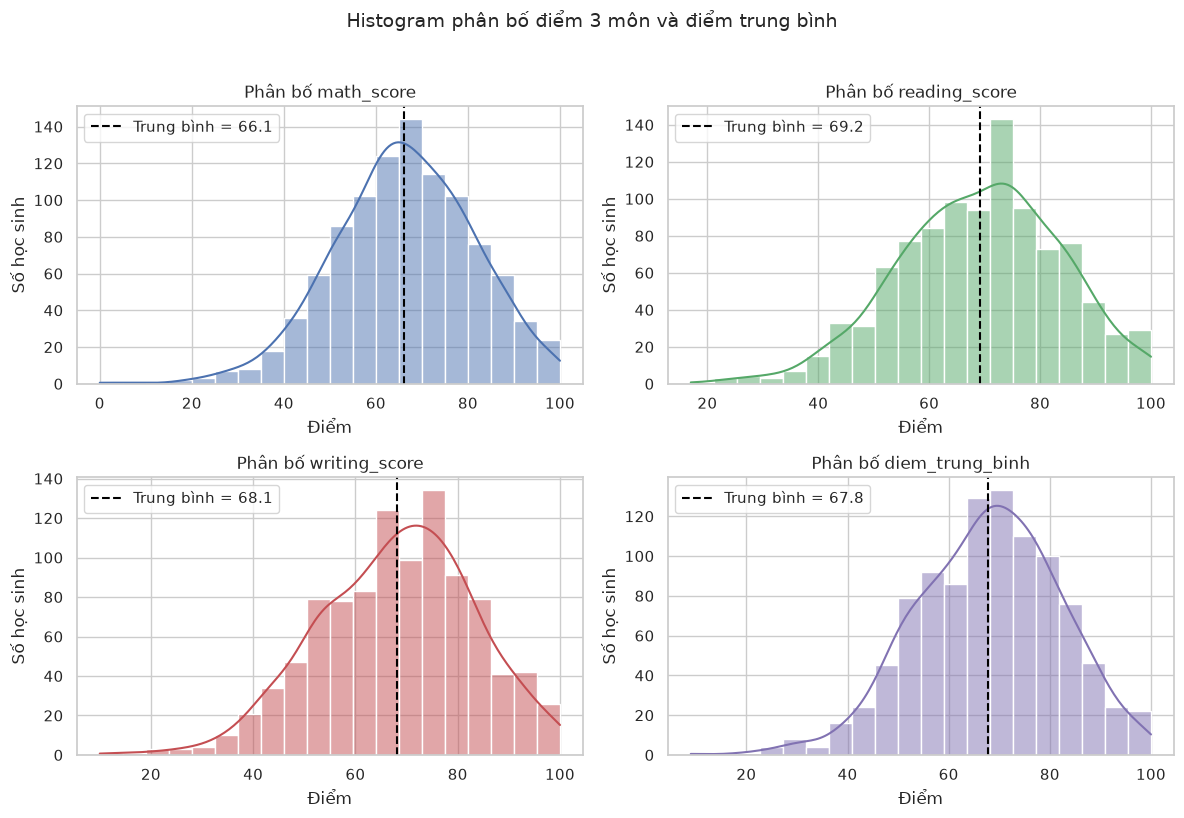

        math_score  reading_score  writing_score  diem_trung_binh
mean         66.09          69.17          68.05            67.77
median       66.00          70.00          69.00            68.33
std          15.16          14.60          15.20            14.26
skew         -0.28          -0.26          -0.29            -0.30
min           0.00          17.00          10.00             9.00
max         100.00         100.00         100.00           100.00


**Nhận xét:** Điểm trung bình của math, reading, writing lần lượt là 66.09, 69.17, 68.05; điểm trung bình chung là 67.77 (trung vị 68.33, độ lệch chuẩn 14.26). Các cột math_score, reading_score, writing_score, diem_trung_binh có độ lệch âm (đuôi bên trái dài), nghĩa là có một số ít học sinh điểm rất thấp kéo đuôi về bên trái. Điểm thấp nhất của math là 0.0 và của writing là 10.0, trong khi điểm cao nhất của cả ba môn đều gần 100.0.

In [19]:
# 4 cột cần xem phân bố: 3 điểm gốc và điểm trung bình (cột mới của Phần II)
cac_cot = DIEM + [TB]
mau = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

# Tạo lưới 2 x 2 biểu đồ; axes.flat duyệt từng ô theo thứ tự
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cot, m in zip(axes.flat, cac_cot, mau):
    # histplot vẽ histogram; bins là số cột; kde=True vẽ thêm đường mật độ
    sns.histplot(data=df, x=cot, bins=20, kde=True, color=m, ax=ax)
    # Đường nét đứt đánh dấu điểm trung bình
    ax.axvline(df[cot].mean(), color="black", linestyle="--", label=f"Trung bình = {df[cot].mean():.1f}")
    ax.set_title("Phân bố " + cot)
    ax.set_xlabel("Điểm")
    ax.set_ylabel("Số học sinh")
    ax.legend()
fig.suptitle("Histogram phân bố điểm 3 môn và điểm trung bình", fontsize=14, y=1.02)
luu_hinh("3_1_1_histogram")

# Thống kê đi kèm để viết nhận xét
thong_ke = df[cac_cot].agg(["mean", "median", "std", "skew", "min", "max"]).round(2)
print(thong_ke)

# Cột có độ lệch (skew) âm rõ rệt (< -0,1): đuôi bên trái dài, tức có một số học sinh điểm rất thấp
lech_am = [c for c in cac_cot if df[c].skew() < -0.1]
cau_lech = (f"Các cột {', '.join(lech_am)} có độ lệch âm (đuôi bên trái dài), nghĩa là có một số ít học sinh điểm rất thấp kéo đuôi về bên trái. "
            if lech_am else "Các phân bố gần đối xứng, không lệch rõ về phía nào. ")
display(Markdown(
    f"**Nhận xét:** Điểm trung bình của math, reading, writing lần lượt là "
    f"{thong_ke.loc['mean', 'math_score']}, {thong_ke.loc['mean', 'reading_score']}, {thong_ke.loc['mean', 'writing_score']}; "
    f"điểm trung bình chung là {thong_ke.loc['mean', TB]} (trung vị {thong_ke.loc['median', TB]}, độ lệch chuẩn {thong_ke.loc['std', TB]}). "
    + cau_lech +
    f"Điểm thấp nhất của math là {thong_ke.loc['min', 'math_score']} và của writing là {thong_ke.loc['min', 'writing_score']}, "
    f"trong khi điểm cao nhất của cả ba môn đều gần {thong_ke.loc['max', DIEM].max()}."
))

### 3.1.2 Box Plot (so sánh phân bố)

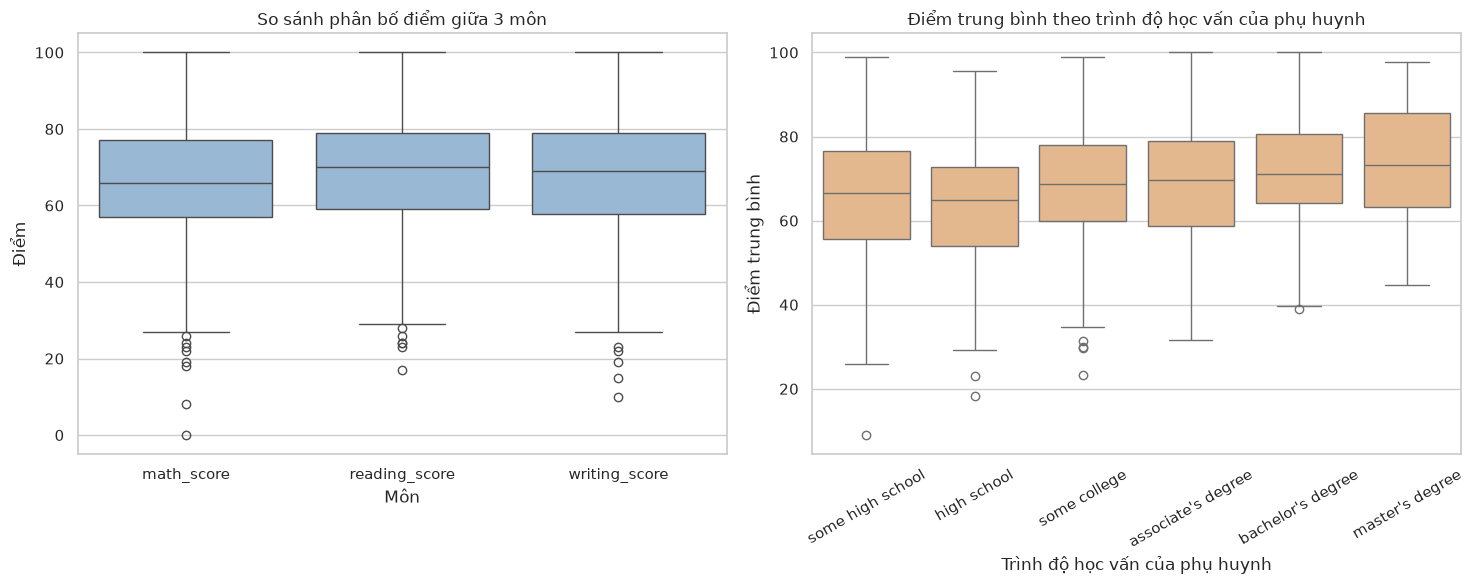

Số ngoại lai: {'math_score': 8, 'reading_score': 6, 'writing_score': 5}
parental_level_of_education
some high school      66.67
high school           65.00
some college          68.67
associate's degree    69.67
bachelor's degree     71.16
master's degree       73.33
Name: diem_trung_binh, dtype: float64


**Nhận xét:** Theo quy tắc 1,5 x IQR có 8 điểm ngoại lai ở math, 6 ở reading và 5 ở writing, trong đó 19/19 ngoại lai nằm ở phía điểm thấp. Theo trình độ học vấn của phụ huynh, trung vị điểm trung bình cao nhất ở nhóm `master's degree` (73.3) và thấp nhất ở nhóm `high school` (65.0), chênh 8.3 điểm; tuy nhiên các hộp của các nhóm chồng lấn nhau nên trình độ phụ huynh không quyết định điểm của từng học sinh.

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) So sánh phân bố của 3 môn: mỗi hộp là một môn
sns.boxplot(data=df[DIEM], color="#8FB8DE", ax=axes[0])
axes[0].set_title("So sánh phân bố điểm giữa 3 môn")
axes[0].set_xlabel("Môn")
axes[0].set_ylabel("Điểm")

# (b) So sánh phân bố điểm trung bình giữa các nhóm trình độ học vấn của phụ huynh (theo thứ tự tăng dần)
sns.boxplot(data=df, x="parental_level_of_education", y=TB, order=THU_TU_HOC_VAN, color="#F2B880", ax=axes[1])
axes[1].set_title("Điểm trung bình theo trình độ học vấn của phụ huynh")
axes[1].set_xlabel("Trình độ học vấn của phụ huynh")
axes[1].set_ylabel("Điểm trung bình")
axes[1].tick_params(axis="x", rotation=30)
luu_hinh("3_1_2_boxplot")

# Đếm ngoại lai theo quy tắc 1.5 x IQR (điểm nằm ngoài [Q1 - 1.5 IQR, Q3 + 1.5 IQR])
def so_ngoai_lai(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

ngoai_lai = {c: so_ngoai_lai(df[c]) for c in DIEM}
# Số ngoại lai nằm ở phía điểm thấp (dưới Q1 - 1.5 IQR) của cả 3 môn
def so_ngoai_lai_thap(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int((s < q1 - 1.5 * (q3 - q1)).sum())
tong_lai = sum(ngoai_lai.values())
tong_lai_thap = sum(so_ngoai_lai_thap(df[c]) for c in DIEM)
trung_vi = df.groupby("parental_level_of_education")[TB].median().reindex(THU_TU_HOC_VAN)
print("Số ngoại lai:", ngoai_lai)
print(trung_vi.round(2))
display(Markdown(
    f"**Nhận xét:** Theo quy tắc 1,5 x IQR có {ngoai_lai['math_score']} điểm ngoại lai ở math, {ngoai_lai['reading_score']} ở reading và "
    f"{ngoai_lai['writing_score']} ở writing, trong đó {tong_lai_thap}/{tong_lai} ngoại lai nằm ở phía điểm thấp. "
    f"Theo trình độ học vấn của phụ huynh, trung vị điểm trung bình cao nhất ở nhóm `{trung_vi.idxmax()}` ({trung_vi.max():.1f}) "
    f"và thấp nhất ở nhóm `{trung_vi.idxmin()}` ({trung_vi.min():.1f}), chênh {trung_vi.max() - trung_vi.min():.1f} điểm; "
    f"tuy nhiên các hộp của các nhóm chồng lấn nhau nên trình độ phụ huynh không quyết định điểm của từng học sinh."
))

## 3.2 So sánh Dữ liệu Định tính (Categorical Comparison)

#### Bar Plot so sánh điểm giữa các nhóm, Pie Chart hiển thị tỷ lệ của cột `xep_loai` (cột mới tạo ở Phần II).

### 3.2.1 Bar Plot

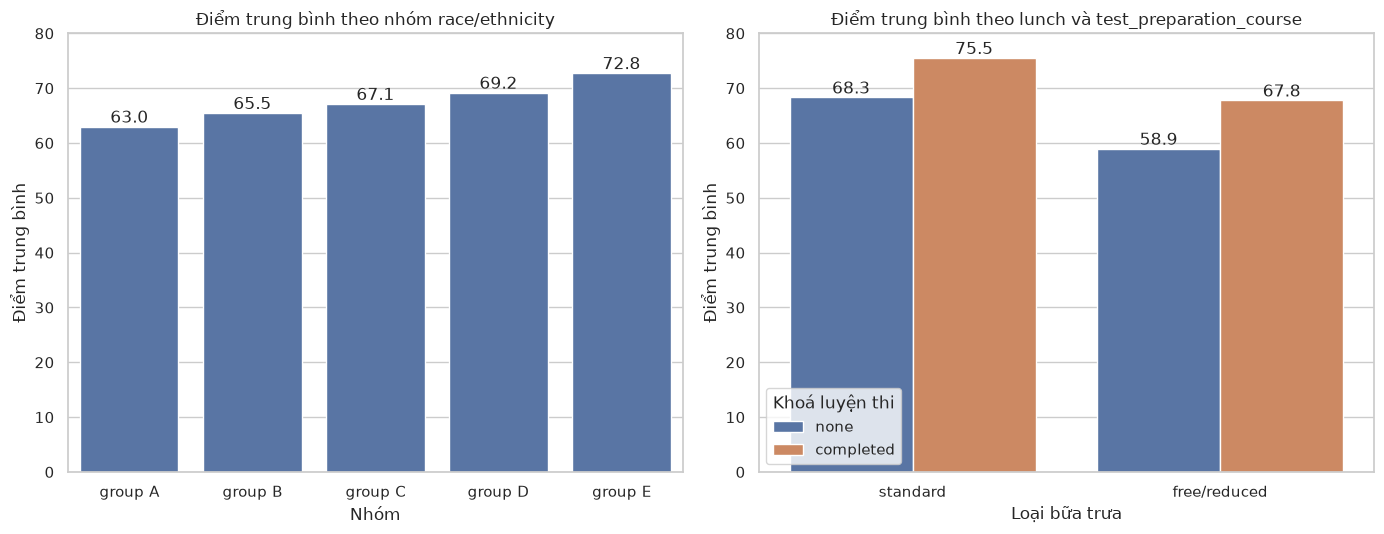

**Nhận xét:** Theo `race_ethnicity`, nhóm `group E` có điểm trung bình cao nhất (72.8) và nhóm `group A` thấp nhất (63.0), chênh 9.8 điểm. Theo `lunch`, nhóm `standard` cao hơn nhóm `free/reduced` 8.6 điểm; theo `test_preparation_course`, nhóm `completed` cao hơn nhóm `none` 7.6 điểm. Ở biểu đồ (b), trong cả hai loại bữa trưa, nhóm đã hoàn thành luyện thi đều có cột cao hơn, tức hai yếu tố này cùng tác động lên điểm.

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Điểm trung bình theo nhóm race_ethnicity (A đến E)
thu_tu_nhom = sorted(df[GROUP_COL].unique())
# errorbar=None bỏ thanh sai số để nhãn số không bị đè
sns.barplot(data=df, x=GROUP_COL, y=TB, order=thu_tu_nhom, color="#4C72B0", errorbar=None, ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f")      # ghi giá trị trên đầu mỗi cột
axes[0].set_ylim(0, 80)
axes[0].set_title("Điểm trung bình theo nhóm race/ethnicity")
axes[0].set_xlabel("Nhóm")
axes[0].set_ylabel("Điểm trung bình")

# (b) Điểm trung bình theo loại bữa trưa, tách theo khoá luyện thi (hue)
sns.barplot(data=df, x="lunch", y=TB, hue="test_preparation_course", errorbar=None, ax=axes[1])
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.1f")
axes[1].set_ylim(0, 80)
axes[1].set_title("Điểm trung bình theo lunch và test_preparation_course")
axes[1].set_xlabel("Loại bữa trưa")
axes[1].set_ylabel("Điểm trung bình")
axes[1].legend(title="Khoá luyện thi")
luu_hinh("3_2_1_barplot")

tb_nhom = df.groupby(GROUP_COL)[TB].mean()
tb_lunch = df.groupby("lunch")[TB].mean()
tb_luyen = df.groupby("test_preparation_course")[TB].mean()
# Kiểm tra: trong từng loại bữa trưa, nhóm có luyện thi (completed) có điểm cao hơn nhóm none không
tb_2_chieu = df.pivot_table(index="lunch", columns="test_preparation_course", values=TB, aggfunc="mean")
luyen_thi_cao_hon = bool((tb_2_chieu["completed"] > tb_2_chieu["none"]).all())
display(Markdown(
    f"**Nhận xét:** Theo `race_ethnicity`, nhóm `{tb_nhom.idxmax()}` có điểm trung bình cao nhất ({tb_nhom.max():.1f}) và nhóm `{tb_nhom.idxmin()}` thấp nhất ({tb_nhom.min():.1f}), "
    f"chênh {tb_nhom.max() - tb_nhom.min():.1f} điểm. "
    f"Theo `lunch`, nhóm `{tb_lunch.idxmax()}` cao hơn nhóm `{tb_lunch.idxmin()}` {tb_lunch.max() - tb_lunch.min():.1f} điểm; "
    f"theo `test_preparation_course`, nhóm `{tb_luyen.idxmax()}` cao hơn nhóm `{tb_luyen.idxmin()}` {tb_luyen.max() - tb_luyen.min():.1f} điểm. "
    + ("Ở biểu đồ (b), trong cả hai loại bữa trưa, nhóm đã hoàn thành luyện thi đều có cột cao hơn, tức hai yếu tố này cùng tác động lên điểm."
       if luyen_thi_cao_hon else "Ở biểu đồ (b), tác động của khoá luyện thi không đồng nhất giữa hai loại bữa trưa.")
))

### 3.2.2 Pie Chart (tỷ lệ phần trăm của `xep_loai` và `ket_qua`)

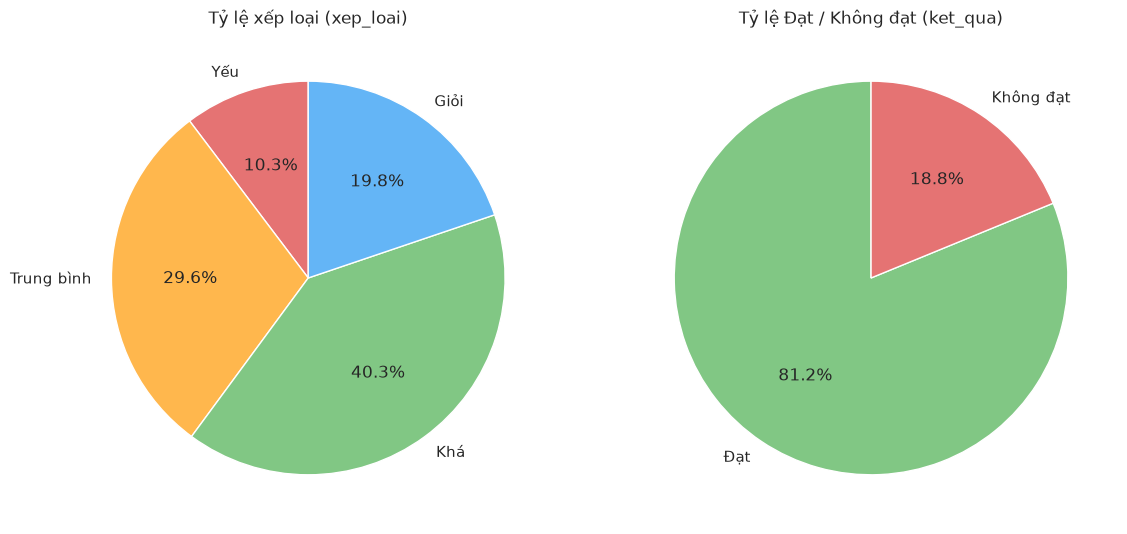

**Nhận xét:** Nhóm xếp loại chiếm tỷ lệ lớn nhất là `Khá` (40.3%), nhóm nhỏ nhất là `Yếu` (10.3%). Tỷ lệ Yếu / Trung bình / Khá / Giỏi lần lượt là 10.3% / 29.6% / 40.3% / 19.8%. Về kết quả, có 81.2% học sinh Đạt (cả 3 môn từ 50 điểm trở lên) và 18.8% Không đạt.

In [22]:

# value_counts() đếm số học sinh của từng nhóm; reindex() sắp theo thứ tự Yếu, Trung bình, Khá, Giỏi
dem_xep_loai = df["xep_loai"].value_counts().reindex(THU_TU_XEP_LOAI)
dem_ket_qua = df["ket_qua"].value_counts().reindex(["Đạt", "Không đạt"])     # cố định thứ tự để màu xanh = Đạt, đỏ = Không đạt

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
# plot.pie của Pandas; autopct ghi phần trăm lên từng miếng; startangle=90 bắt đầu từ đỉnh
dem_xep_loai.plot.pie(ax=axes[0], autopct="%1.1f%%", startangle=90, ylabel="",
                      colors=["#E57373", "#FFB74D", "#81C784", "#64B5F6"], wedgeprops={"edgecolor": "white"})
axes[0].set_title("Tỷ lệ xếp loại (xep_loai)")
dem_ket_qua.plot.pie(ax=axes[1], autopct="%1.1f%%", startangle=90, ylabel="",
                     colors=["#81C784", "#E57373"], wedgeprops={"edgecolor": "white"})
axes[1].set_title("Tỷ lệ Đạt / Không đạt (ket_qua)")
luu_hinh("3_2_2_piechart")

ty_le = (dem_xep_loai / dem_xep_loai.sum() * 100).round(1)
ty_le_kq = (dem_ket_qua / dem_ket_qua.sum() * 100).round(1)
display(Markdown(
    f"**Nhận xét:** Nhóm xếp loại chiếm tỷ lệ lớn nhất là `{ty_le.idxmax()}` ({ty_le.max()}%), nhóm nhỏ nhất là `{ty_le.idxmin()}` ({ty_le.min()}%). "
    f"Tỷ lệ Yếu / Trung bình / Khá / Giỏi lần lượt là {ty_le['Yếu']}% / {ty_le['Trung bình']}% / {ty_le['Khá']}% / {ty_le['Giỏi']}%. "
    f"Về kết quả, có {ty_le_kq.get('Đạt', 0)}% học sinh Đạt (cả 3 môn từ 50 điểm trở lên) và {ty_le_kq.get('Không đạt', 0)}% Không đạt."
))

## 3.3 Mối quan hệ và Xu hướng (Relationship and Trend)

#### Scatter Plot kèm đường hồi quy (regression line) bằng Seaborn.

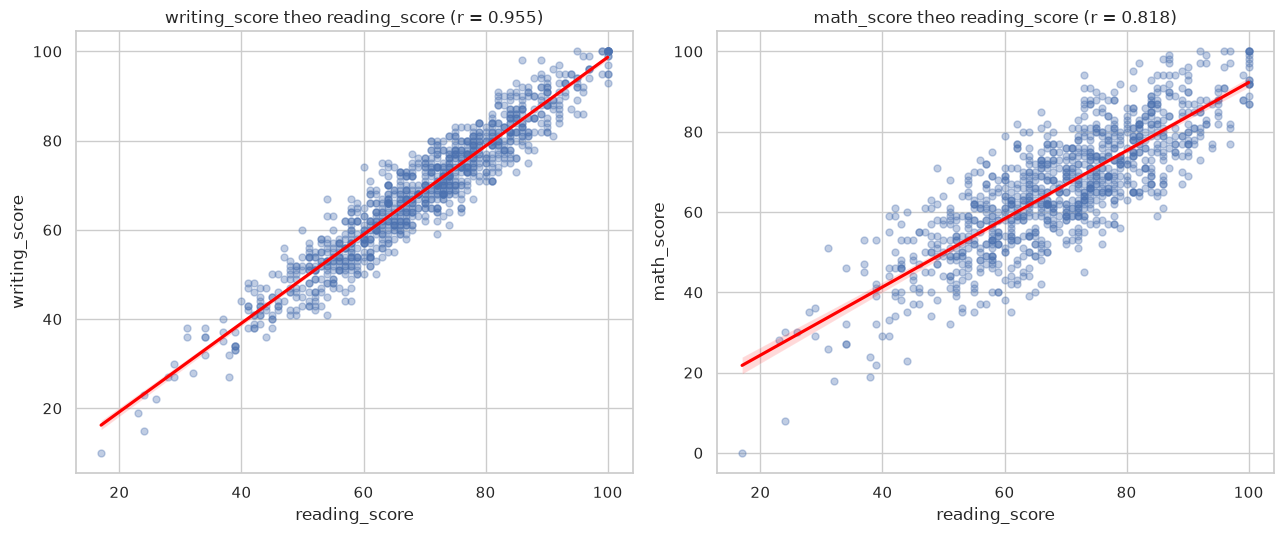

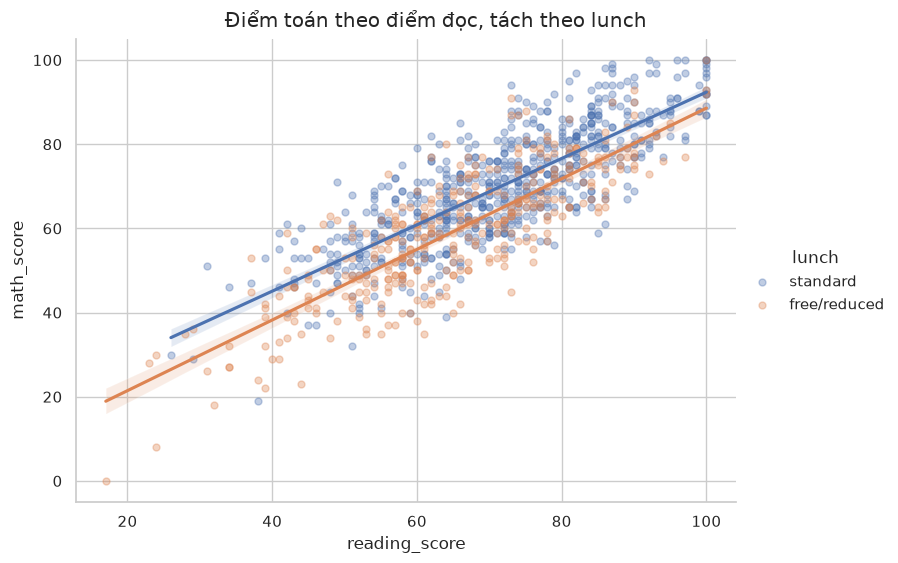

**Nhận xét:** Reading và writing có tương quan dương (r = 0.955); mỗi +1 điểm reading ứng với khoảng +0.99 điểm writing. Reading và math có r = 0.818 (hệ số góc khoảng 0.85), thấp hơn cặp reading - writing nên điểm đọc dự đoán điểm toán kém chính xác hơn dự đoán điểm viết. Khi tách theo `lunch`, ở cùng mức điểm đọc 70 thì điểm toán dự đoán là free/reduced: 63.4; standard: 68.7 (chênh 5.3 điểm), tức đây là khoảng cách giữa hai đường hồi quy ở cùng điểm đọc.

In [23]:
# Hai cặp biến: (đọc, viết) và (đọc, toán)
cap_bien = [("reading_score", "writing_score"), ("reading_score", "math_score")]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (x, y) in zip(axes, cap_bien):
    # regplot vẽ scatter và đường hồi quy tuyến tính; alpha làm điểm mờ để thấy chỗ chồng nhau
    sns.regplot(data=df, x=x, y=y, scatter_kws={"alpha": 0.35, "s": 25}, line_kws={"color": "red"}, ax=ax)
    r = df[x].corr(df[y])      # hệ số tương quan Pearson
    ax.set_title(f"{y} theo {x} (r = {r:.3f})")
luu_hinh("3_3_scatter_regplot")

# Hệ số góc của đường hồi quy: mỗi +1 điểm đọc thì điểm viết / toán tăng thêm bao nhiêu
he_so = {y: np.polyfit(df[x], df[y], 1)[0] for x, y in cap_bien}

# Tách đường hồi quy theo từng loại bữa trưa (hue) để xem xu hướng có khác nhau giữa hai nhóm không
g = sns.lmplot(data=df, x="reading_score", y="math_score", hue="lunch", height=5.5, aspect=1.4,
               scatter_kws={"alpha": 0.35, "s": 25})
g.figure.suptitle("Điểm toán theo điểm đọc, tách theo lunch", y=1.02)
g.savefig(os.path.join(CHART_FOLDER, "3_3_lmplot_lunch.png"), dpi=150, bbox_inches="tight")
plt.show()

# Điểm toán dự đoán ở cùng mức điểm đọc = 70 của từng nhóm lunch
du_doan = {nhom: np.polyval(np.polyfit(d["reading_score"], d["math_score"], 1), 70) for nhom, d in df.groupby("lunch")}
r_doc_viet = df["reading_score"].corr(df["writing_score"])
r_doc_toan = df["reading_score"].corr(df["math_score"]) 
display(Markdown(
    f"**Nhận xét:** Reading và writing có tương quan dương (r = {r_doc_viet:.3f}); "
    f"mỗi +1 điểm reading ứng với khoảng +{he_so['writing_score']:.2f} điểm writing. "
    f"Reading và math có r = {r_doc_toan:.3f} (hệ số góc khoảng {he_so['math_score']:.2f}), "
    + ("thấp hơn cặp reading - writing nên điểm đọc dự đoán điểm toán kém chính xác hơn dự đoán điểm viết. " if r_doc_toan < r_doc_viet
       else "không thấp hơn cặp reading - writing. ") +
    f"Khi tách theo `lunch`, ở cùng mức điểm đọc 70 thì điểm toán dự đoán là "
    + "; ".join(f"{nhom}: {v:.1f}" for nhom, v in du_doan.items())
    + f" (chênh {max(du_doan.values()) - min(du_doan.values()):.1f} điểm), tức đây là khoảng cách giữa hai đường hồi quy ở cùng điểm đọc."
))

## 3.4 Trực quan hoá cơ bản (Matplotlib Core)

#### Chỉ dùng Matplotlib và cấu trúc Python cơ bản (list, dictionary), không dùng Pandas/Seaborn để vẽ.

Chọn 5 học sinh đầu tiên, vẽ biểu đồ thanh cho điểm trung bình và biểu đồ đường cho điểm từng môn.

Điểm trung bình: [72.67, 82.33, 92.67, 49.33, 76.33]
Điểm từng môn: {'Toán': [72, 69, 90, 47, 76], 'Đọc': [72, 90, 95, 57, 78], 'Viết': [74, 88, 93, 44, 75]}


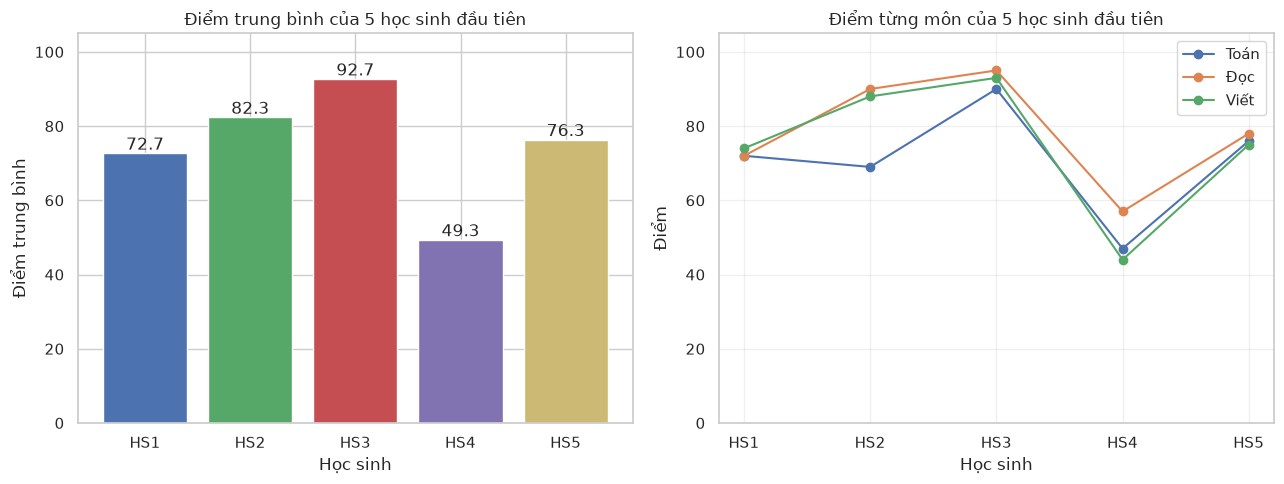

**Nhận xét:** Trong 5 học sinh đầu tiên, `HS3` có điểm trung bình cao nhất (92.7) và `HS4` thấp nhất (49.3). Ba đường điểm của các môn có hình dạng khá giống nhau giữa các học sinh, phù hợp với tương quan dương mạnh giữa ba môn ở Phần II.

In [24]:
# Lấy dữ liệu của 5 học sinh đầu tiên ra list và dictionary thuần của Python (chỉ bước này đụng đến DataFrame)
ten_hs = ["HS1", "HS2", "HS3", "HS4", "HS5"]
diem_tb = df[TB].head(5).tolist()                                  # list điểm trung bình
diem_mon = {"Toán": df["math_score"].head(5).tolist(),             # dictionary: tên môn -> list điểm
            "Đọc": df["reading_score"].head(5).tolist(),
            "Viết": df["writing_score"].head(5).tolist()}
print("Điểm trung bình:", diem_tb)
print("Điểm từng môn:", diem_mon)

# Từ đây chỉ dùng matplotlib và Python cơ bản
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) Biểu đồ thanh: điểm trung bình của 5 học sinh
mau_cot = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]
axes[0].bar(ten_hs, diem_tb, color=mau_cot)
for ten, gia_tri in zip(ten_hs, diem_tb):               # ghi giá trị lên đầu mỗi cột bằng vòng lặp
    axes[0].text(ten, gia_tri + 1, f"{gia_tri:.1f}", ha="center")
axes[0].set_ylim(0, 105)
axes[0].set_title("Điểm trung bình của 5 học sinh đầu tiên")
axes[0].set_xlabel("Học sinh")
axes[0].set_ylabel("Điểm trung bình")

# (b) Biểu đồ đường: mỗi môn là một đường (duyệt dictionary bằng .items())
for mon, ds in diem_mon.items():
    axes[1].plot(ten_hs, ds, marker="o", label=mon)
axes[1].set_ylim(0, 105)
axes[1].set_title("Điểm từng môn của 5 học sinh đầu tiên")
axes[1].set_xlabel("Học sinh")
axes[1].set_ylabel("Điểm")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
luu_hinh("3_4_matplotlib_core")

# Nhận xét bằng Python cơ bản: max, min, index trên list
hs_cao = ten_hs[diem_tb.index(max(diem_tb))]
hs_thap = ten_hs[diem_tb.index(min(diem_tb))]
display(Markdown(
    f"**Nhận xét:** Trong 5 học sinh đầu tiên, `{hs_cao}` có điểm trung bình cao nhất ({max(diem_tb):.1f}) và `{hs_thap}` thấp nhất ({min(diem_tb):.1f}). "
    f"Ba đường điểm của các môn có hình dạng khá giống nhau giữa các học sinh, phù hợp với tương quan dương mạnh giữa ba môn ở Phần II."
))

# PHẦN IV: TỔNG HỢP VÀ BÁO CÁO

## 4.1 Báo cáo toàn diện: hàm `comprehensive_report()`

#### Hiển thị tổng số record, phân bố (số lượng và tỷ lệ phần trăm), thống kê điểm và các điểm nổi bật.

In [25]:
def comprehensive_report(data, score_cols=None, cat_cols=None):
    """In báo cáo tổng hợp: tổng số record, phân bố (số lượng và %) của các cột phân loại,
    thống kê của các cột điểm và các điểm nổi bật."""
    # Giá trị mặc định cho các tham số
    if score_cols is None:
        score_cols = DIEM + [TB]
    if cat_cols is None:
        cat_cols = CAC_YEU_TO + ["xep_loai", "ket_qua"]
    tong = len(data)

    # ---------- 1. Tổng quan ----------
    print("=" * 70)
    print("BÁO CÁO TỔNG HỢP")
    print("=" * 70)
    print("1. TỔNG QUAN")
    print("   Tổng số record     :", tong)
    print("   Số cột             :", data.shape[1])
    print("   Giá trị thiếu      :", int(data.isnull().sum().sum()))
    print("   Dòng trùng         :", int(data.duplicated().sum()))

    # ---------- 2. Phân bố các cột phân loại (số lượng và %) ----------
    print("\n2. PHÂN BỐ CÁC CỘT PHÂN LOẠI (số lượng và tỷ lệ %)")
    for cot in cat_cols:
        dem = data[cot].value_counts()
        if cot in THU_TU:                                # cột có thứ bậc thì sắp đúng thứ tự
            dem = dem.reindex(THU_TU[cot])
        bang = pd.DataFrame({"số lượng": dem, "tỷ lệ (%)": (dem / tong * 100).round(1)})
        print(f"\n   --- {cot} ---")
        print(bang.to_string())

    # ---------- 3. Thống kê các cột điểm ----------
    print("\n3. THỐNG KÊ CÁC CỘT ĐIỂM")
    print(data[score_cols].agg(["mean", "median", "std", "min", "max"]).round(2).T.to_string())

    # ---------- 4. Điểm nổi bật ----------
    tb_mon = data[DIEM].mean()
    print("\n4. ĐIỂM NỔI BẬT")
    print(f"   Môn có điểm TB cao nhất : {tb_mon.idxmax()} ({tb_mon.max():.2f})")
    print(f"   Môn có điểm TB thấp nhất: {tb_mon.idxmin()} ({tb_mon.min():.2f})")
    print(f"   Điểm trung bình cao nhất / thấp nhất của một học sinh: {data[TB].max():.2f} / {data[TB].min():.2f}")
    so_hoc_sinh_100 = int((data[DIEM] == 100).any(axis=1).sum())
    print(f"   Số học sinh có ít nhất một môn đạt 100 điểm: {so_hoc_sinh_100}")
    print("=" * 70)

# Gọi hàm với dữ liệu sau Phần II
comprehensive_report(df)

BÁO CÁO TỔNG HỢP
1. TỔNG QUAN
   Tổng số record     : 1000
   Số cột             : 18
   Giá trị thiếu      : 0
   Dòng trùng         : 0

2. PHÂN BỐ CÁC CỘT PHÂN LOẠI (số lượng và tỷ lệ %)

   --- gender ---
        số lượng  tỷ lệ (%)
gender                     
female       518       51.8
male         482       48.2

   --- race_ethnicity ---
                số lượng  tỷ lệ (%)
race_ethnicity                     
group C              319       31.9
group D              262       26.2
group B              190       19.0
group E              140       14.0
group A               89        8.9

   --- parental_level_of_education ---
                             số lượng  tỷ lệ (%)
parental_level_of_education                     
some high school                  179       17.9
high school                       196       19.6
some college                      226       22.6
associate's degree                222       22.2
bachelor's degree                 118       11.8
master's degree  

## 4.2 Phân tích chuyên sâu: 10 học sinh cao nhất và thấp nhất

#### Xếp hạng theo cột `diem_trung_binh`, hiển thị đầy đủ tất cả các cột.

In [26]:
# Hiển thị đầy đủ mọi cột (không bị rút gọn bằng dấu ...)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

COT_XEP_HANG = TB     # cột dùng để xếp hạng
# kind="mergesort" là sắp xếp ổn định: các học sinh bằng điểm giữ nguyên thứ tự ban đầu, nên kết quả không đổi giữa các lần chạy
top10 = df.sort_values(COT_XEP_HANG, ascending=False, kind="mergesort").head(10)
bottom10 = df.sort_values(COT_XEP_HANG, ascending=True, kind="mergesort").head(10)

print("===== 10 HỌC SINH CÓ", COT_XEP_HANG, "CAO NHẤT =====")
display(top10)
print("\n===== 10 HỌC SINH CÓ", COT_XEP_HANG, "THẤP NHẤT =====")
display(bottom10)

===== 10 HỌC SINH CÓ diem_trung_binh CAO NHẤT =====


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,tong_diem,diem_trung_binh,xep_loai,ket_qua,chuan_bi_num,lunch_num,nam_num,math_minmax,math_zscore,math_minmax_chung
458,female,group E,bachelor's degree,standard,none,100,100,100,300,100.00,Giỏi,Đạt,0,1,0,1.000000,1.685215,1.00
916,male,group E,bachelor's degree,standard,completed,100,100,100,300,100.00,Giỏi,Đạt,1,1,1,1.000000,1.685215,1.00
962,female,group E,associate's degree,standard,none,100,100,100,300,100.00,Giỏi,Đạt,0,1,0,1.000000,1.685215,1.00
114,female,group E,bachelor's degree,standard,completed,99,100,100,299,99.67,Giỏi,Đạt,1,1,0,0.985714,1.620841,0.99
179,female,group D,some high school,standard,completed,97,100,100,297,99.00,Giỏi,Đạt,1,1,0,0.959459,2.152413,0.97
712,female,group D,some college,standard,none,98,100,99,297,99.00,Giỏi,Đạt,0,1,0,0.972973,2.225038,0.98
165,female,group C,bachelor's degree,standard,completed,96,100,100,296,98.67,Giỏi,Đạt,1,1,0,0.979592,2.123259,0.96
625,male,group D,some college,standard,completed,100,97,99,296,98.67,Giỏi,Đạt,1,1,1,1.000000,2.370288,1.00
149,male,group E,associate's degree,free/reduced,completed,100,100,93,293,97.67,Giỏi,Đạt,1,0,1,1.000000,1.685215,1.00
685,female,group E,master's degree,standard,completed,94,99,100,293,97.67,Giỏi,Đạt,1,1,0,0.914286,1.298972,0.94



===== 10 HỌC SINH CÓ diem_trung_binh THẤP NHẤT =====


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,tong_diem,diem_trung_binh,xep_loai,ket_qua,chuan_bi_num,lunch_num,nam_num,math_minmax,math_zscore,math_minmax_chung
59,female,group C,some high school,free/reduced,none,0,17,10,27,9.00,Yếu,Không đạt,0,0,0,0.000000,-4.340228,0.00
980,female,group B,high school,free/reduced,none,8,24,23,55,18.33,Yếu,Không đạt,0,0,0,0.000000,-3.584946,0.08
596,male,group B,high school,free/reduced,none,30,24,15,69,23.00,Yếu,Không đạt,0,0,1,0.247191,-2.162672,0.30
327,male,group A,some college,free/reduced,none,28,23,19,70,23.33,Yếu,Không đạt,0,0,1,0.000000,-2.315582,0.28
17,female,group B,some high school,free/reduced,none,18,32,28,78,26.00,Yếu,Không đạt,0,0,0,0.112360,-2.938458,0.18
76,male,group E,some high school,standard,none,30,26,22,78,26.00,Yếu,Không đạt,0,1,1,0.000000,-2.820954,0.30
601,female,group C,high school,standard,none,29,29,30,88,29.33,Yếu,Không đạt,0,1,0,0.295918,-2.387716,0.29
338,female,group B,some high school,free/reduced,none,24,38,27,89,29.67,Yếu,Không đạt,0,0,0,0.179775,-2.550565,0.24
787,female,group B,some college,standard,none,19,38,32,89,29.67,Yếu,Không đạt,0,1,0,0.123596,-2.873809,0.19
211,male,group C,some college,free/reduced,none,35,28,27,90,30.00,Yếu,Không đạt,0,0,1,0.357143,-1.983748,0.35


In [27]:
# So sánh đặc điểm của hai nhóm: đếm số học sinh theo từng giá trị của các cột phân loại
for cot in ["lunch", "test_preparation_course", "gender"]:
    bang = pd.concat([top10[cot].value_counts(), bottom10[cot].value_counts()], axis=1, keys=["Top 10", "Bottom 10"])
    print(f"\n--- {cot} ---")
    print(bang.fillna(0).astype(int).to_string())

top_std = int((top10["lunch"] == "standard").sum())
bot_std = int((bottom10["lunch"] == "standard").sum())
top_lt = int((top10["test_preparation_course"] == "completed").sum())
bot_lt = int((bottom10["test_preparation_course"] == "completed").sum())
display(Markdown(
    f"**Nhận xét:** Nhóm 10 học sinh cao nhất có điểm trung bình từ {top10[COT_XEP_HANG].min():.2f} đến {top10[COT_XEP_HANG].max():.2f}, "
    f"nhóm thấp nhất từ {bottom10[COT_XEP_HANG].min():.2f} đến {bottom10[COT_XEP_HANG].max():.2f}. "
    f"Trong top 10 có {top_std}/10 học sinh ăn trưa `standard` và {top_lt}/10 đã hoàn thành khoá luyện thi; "
    f"trong bottom 10 các con số này là {bot_std}/10 và {bot_lt}/10. "
    f"Lưu ý đây chỉ là 20 học sinh nên chỉ mang tính minh hoạ, kết luận chính dựa trên toàn bộ dữ liệu ở mục 4.3."
))


--- lunch ---
              Top 10  Bottom 10
lunch                          
standard           9          3
free/reduced       1          7

--- test_preparation_course ---
                         Top 10  Bottom 10
test_preparation_course                   
completed                     7          0
none                          3         10

--- gender ---
        Top 10  Bottom 10
gender                   
female       7          6
male         3          4


**Nhận xét:** Nhóm 10 học sinh cao nhất có điểm trung bình từ 97.67 đến 100.00, nhóm thấp nhất từ 9.00 đến 30.00. Trong top 10 có 9/10 học sinh ăn trưa `standard` và 7/10 đã hoàn thành khoá luyện thi; trong bottom 10 các con số này là 3/10 và 0/10. Lưu ý đây chỉ là 20 học sinh nên chỉ mang tính minh hoạ, kết luận chính dựa trên toàn bộ dữ liệu ở mục 4.3.

## 4.3 Yếu tố nào ảnh hưởng lớn nhất đến điểm số?

#### Biến phụ thuộc: `diem_trung_binh` (và từng môn). Biến độc lập: `gender`, `race_ethnicity`, `parental_level_of_education`, `lunch`, `test_preparation_course`.

Dùng ba thước đo bổ sung cho nhau:

- **Eta bình phương (η²):** tỷ lệ phương sai của điểm được giải thích riêng bởi một yếu tố, tính bằng `groupby` và `transform` (từ 0% đến 100%).
- **ΔR²:** mức R² của mô hình hồi quy tuyến tính (đủ 5 yếu tố) **giảm đi** khi bỏ riêng yếu tố đó, tức phần đóng góp riêng của yếu tố khi đã tính đến 4 yếu tố còn lại.
- **Chênh lệch nhóm:** hiệu giữa điểm trung bình của nhóm cao nhất và nhóm thấp nhất của yếu tố.

In [28]:
def eta_squared(data, cot_nhom, cot_diem):
    """Tỷ lệ phương sai của cot_diem được giải thích bởi cot_nhom (từ 0 đến 1)."""
    tb_chung = data[cot_diem].mean()
    ss_tong = ((data[cot_diem] - tb_chung) ** 2).sum()                          # tổng bình phương độ lệch toàn bộ
    tb_nhom = data.groupby(cot_nhom)[cot_diem].transform("mean")                 # trung bình của nhóm mà mỗi học sinh thuộc về
    ss_giua = ((tb_nhom - tb_chung) ** 2).sum()                                  # phần độ lệch do khác biệt giữa các nhóm
    return ss_giua / ss_tong

def r_binh_phuong(data, cac_yeu_to, cot_diem):
    """R^2 của hồi quy tuyến tính cot_diem theo các yếu tố (mã hoá one-hot), giải bằng bình phương tối thiểu."""
    X = pd.get_dummies(data[cac_yeu_to], drop_first=True).astype(float)         # biến chữ thành các cột 0/1
    X.insert(0, "hang_so", 1.0)                                                 # cột hằng số (intercept)
    y = data[cot_diem].to_numpy(dtype=float)
    beta = np.linalg.lstsq(X.to_numpy(), y, rcond=None)[0]                      # hệ số hồi quy
    phan_du = y - X.to_numpy() @ beta
    return 1 - (phan_du ** 2).sum() / ((y - y.mean()) ** 2).sum()

# ---------- Thước đo 1: eta^2 (%) cho điểm trung bình và từng môn ----------
bang_eta = pd.DataFrame({cot_diem: {yt: eta_squared(df, yt, cot_diem) * 100 for yt in CAC_YEU_TO}
                         for cot_diem in DIEM + [TB]})
bang_eta = bang_eta.sort_values(TB, ascending=False).round(2)
print("η² (%) = phần trăm phương sai điểm được giải thích bởi từng yếu tố")
print(bang_eta)

# ---------- Thước đo 2: Delta R^2 khi bỏ từng yếu tố khỏi mô hình ----------
r2_day_du = r_binh_phuong(df, CAC_YEU_TO, TB)
delta_r2 = {yt: (r2_day_du - r_binh_phuong(df, [k for k in CAC_YEU_TO if k != yt], TB)) * 100 for yt in CAC_YEU_TO}

# ---------- Thước đo 3: chênh lệch điểm trung bình giữa nhóm cao nhất và thấp nhất ----------
chenh_lech = {}
for yt in CAC_YEU_TO:
    tb_nhom = df.groupby(yt)[TB].mean()
    chenh_lech[yt] = tb_nhom.max() - tb_nhom.min()

# Gộp 3 thước đo vào một bảng, xếp theo η²
bang_tong_hop = pd.DataFrame({"eta2_pct": bang_eta[TB],
                              "delta_r2_pct": pd.Series(delta_r2),
                              "chenh_lech_nhom": pd.Series(chenh_lech)}).sort_values("eta2_pct", ascending=False).round(2)
print("\nR² của mô hình đủ 5 yếu tố:", round(r2_day_du * 100, 2), "%")
print(bang_tong_hop)

η² (%) = phần trăm phương sai điểm được giải thích bởi từng yếu tố
                             math_score  reading_score  writing_score  diem_trung_binh
lunch                             12.31           5.27           6.04             8.41
test_preparation_course            3.16           5.85           9.79             6.59
parental_level_of_education        3.18           4.46           6.77             5.13
race_ethnicity                     5.54           2.21           2.80             3.53
gender                             2.82           5.97           9.07             1.71

R² của mô hình đủ 5 yếu tố: 24.23 %
                             eta2_pct  delta_r2_pct  chenh_lech_nhom
lunch                            8.41          8.63             8.64
test_preparation_course          6.59          6.50             7.63
parental_level_of_education      5.13          4.19            10.50
race_ethnicity                   3.53          2.20             9.76
gender                       

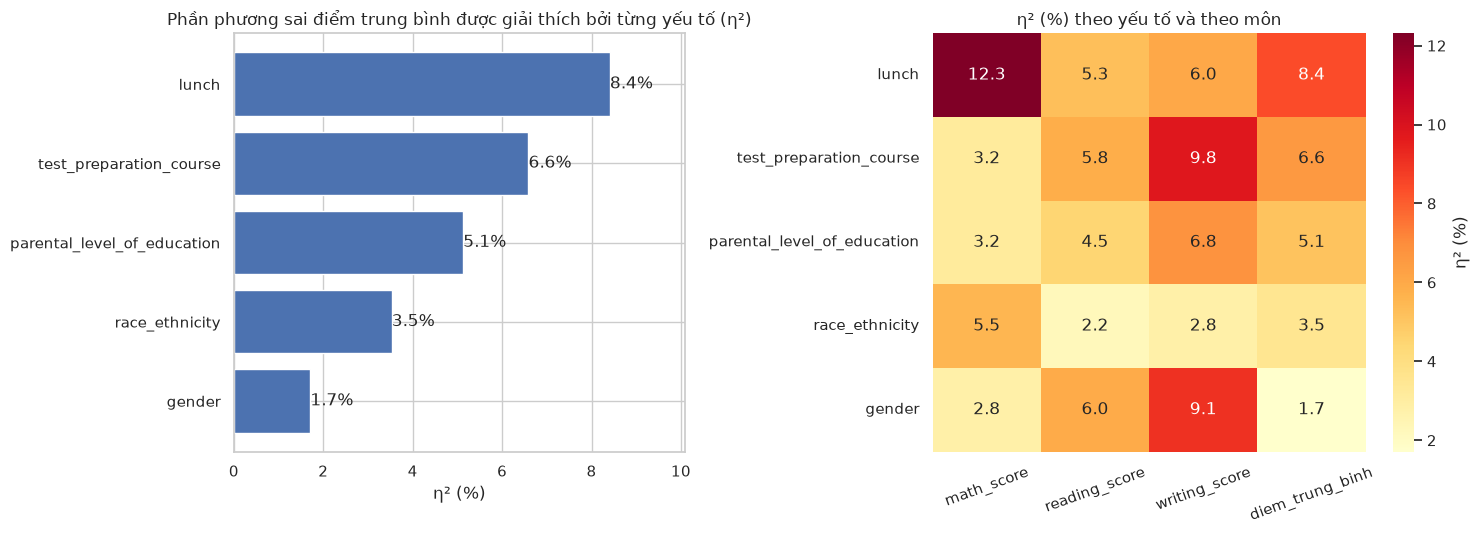

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})

# (a) Biểu đồ thanh ngang: η² của từng yếu tố đối với điểm trung bình (yếu tố mạnh nhất nằm trên cùng)
sap_xep = bang_tong_hop["eta2_pct"].sort_values()
axes[0].barh(sap_xep.index, sap_xep.values, color="#4C72B0")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%")
axes[0].set_title("Phần phương sai điểm trung bình được giải thích bởi từng yếu tố (η²)")
axes[0].set_xlabel("η² (%)")
axes[0].set_xlim(0, sap_xep.max() * 1.2)     # chừa chỗ bên phải cho nhãn %

# (b) Heatmap: η² của từng yếu tố đối với từng môn, để thấy yếu tố nào tác động môn nào
sns.heatmap(bang_eta, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "η² (%)"}, ax=axes[1])
axes[1].set_title("η² (%) theo yếu tố và theo môn")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=20)     # xoay nhãn trục x để không dính nhau
luu_hinh("4_3_anh_huong")

In [30]:
# ---------- Điểm trung bình theo từng nhóm của yếu tố mạnh nhất, để thấy chiều của tác động ----------
yeu_to_manh = bang_tong_hop["eta2_pct"].idxmax()
print("Điểm trung bình theo", yeu_to_manh)
print(df.groupby(yeu_to_manh)[TB].agg(["count", "mean", "std"]).round(2).sort_values("mean", ascending=False))

# ---------- Kết luận (số liệu lấy trực tiếp từ kết quả tính ở trên) ----------
TEN_VN = {"gender": "giới tính (gender)", "race_ethnicity": "nhóm chủng tộc (race_ethnicity)",
          "parental_level_of_education": "trình độ học vấn của phụ huynh (parental_level_of_education)",
          "lunch": "loại bữa trưa (lunch)", "test_preparation_course": "khoá luyện thi (test_preparation_course)"}
thu_hang = bang_tong_hop["eta2_pct"]
yeu_to_delta = bang_tong_hop["delta_r2_pct"].idxmax()
tb_nhom = df.groupby(yeu_to_manh)[TB].mean().sort_values(ascending=False)
gt = bang_eta.loc["gender"]
tuong_quan_doc_viet = df["reading_score"].corr(df["writing_score"])

dong = [
    f"**Kết luận Phần IV:**",
    f"1. **Biến phụ thuộc** là điểm trung bình (`{TB}`), **biến độc lập có ảnh hưởng lớn nhất** là **{TEN_VN[yeu_to_manh]}**: "
    f"riêng yếu tố này giải thích {thu_hang.max():.1f}% phương sai điểm trung bình, theo sau là {TEN_VN[thu_hang.index[1]]} ({thu_hang.iloc[1]:.1f}%) "
    f"và {TEN_VN[thu_hang.index[2]]} ({thu_hang.iloc[2]:.1f}%); yếu tố yếu nhất là {TEN_VN[thu_hang.index[-1]]} ({thu_hang.iloc[-1]:.1f}%).",
    f"2. Khi tính đến cả 4 yếu tố còn lại (ΔR²), yếu tố đóng góp riêng nhiều nhất là {TEN_VN[yeu_to_delta]} (ΔR² = {bang_tong_hop.loc[yeu_to_delta, 'delta_r2_pct']:.1f}%)"
    + (", **trùng** với kết quả xếp hạng theo η², nên kết luận ở mục 1 khá vững." if yeu_to_delta == yeu_to_manh
       else f", **khác** với xếp hạng theo η² ({yeu_to_manh}), cho thấy một phần ảnh hưởng của yếu tố đó bị chồng lấn với các yếu tố khác."),
    f"3. Chiều tác động: trong yếu tố mạnh nhất, nhóm `{tb_nhom.index[0]}` có điểm trung bình cao nhất ({tb_nhom.iloc[0]:.1f}) và nhóm `{tb_nhom.index[-1]}` thấp nhất ({tb_nhom.iloc[-1]:.1f}), "
    f"chênh {tb_nhom.iloc[0] - tb_nhom.iloc[-1]:.1f} điểm (xem thêm biểu đồ thanh ở 3.2.1 và box plot ở 3.1.2).",
    f"4. `gender` cần xét theo từng môn: η² là {gt['math_score']:.1f}% với math, {gt['reading_score']:.1f}% với reading và {gt['writing_score']:.1f}% với writing. "
    f"Ở Phần II, nam hơn nữ ở toán nhưng kém hơn ở đọc và viết, hai chiều ngược nhau nên bị triệt tiêu một phần khi lấy điểm trung bình.",
    f"5. Cả 5 yếu tố cùng nhau giải thích khoảng {r2_day_du * 100:.1f}% phương sai điểm trung bình; phần còn lại ({100 - r2_day_du * 100:.1f}%) đến từ các yếu tố không có trong dữ liệu "
    f"(thời gian tự học, năng lực nền, chất lượng giảng dạy,...)" + (" nên chỉ dựa vào các cột này thì chưa dự đoán chính xác điểm của từng học sinh." if r2_day_du < 0.5 else "."),
    f"6. Giữa các môn, reading và writing có tương quan rất mạnh (r = {tuong_quan_doc_viet:.3f}), thể hiện ở scatter plot mục 3.3: học sinh giỏi một môn ngôn ngữ thường giỏi môn còn lại.",
    f"7. **Lưu ý:** đây là dữ liệu quan sát nên mối liên hệ không đồng nghĩa với nhân quả. Ví dụ loại bữa trưa nhiều khả năng phản ánh điều kiện kinh tế gia đình chứ không phải bản thân bữa ăn làm điểm thay đổi.",
]
display(Markdown("\n\n".join(dong)))

Điểm trung bình theo lunch
              count   mean    std
lunch                            
standard        645  70.84  13.19
free/reduced    355  62.20  14.46


**Kết luận Phần IV:**

1. **Biến phụ thuộc** là điểm trung bình (`diem_trung_binh`), **biến độc lập có ảnh hưởng lớn nhất** là **loại bữa trưa (lunch)**: riêng yếu tố này giải thích 8.4% phương sai điểm trung bình, theo sau là khoá luyện thi (test_preparation_course) (6.6%) và trình độ học vấn của phụ huynh (parental_level_of_education) (5.1%); yếu tố yếu nhất là giới tính (gender) (1.7%).

2. Khi tính đến cả 4 yếu tố còn lại (ΔR²), yếu tố đóng góp riêng nhiều nhất là loại bữa trưa (lunch) (ΔR² = 8.6%), **trùng** với kết quả xếp hạng theo η², nên kết luận ở mục 1 khá vững.

3. Chiều tác động: trong yếu tố mạnh nhất, nhóm `standard` có điểm trung bình cao nhất (70.8) và nhóm `free/reduced` thấp nhất (62.2), chênh 8.6 điểm (xem thêm biểu đồ thanh ở 3.2.1 và box plot ở 3.1.2).

4. `gender` cần xét theo từng môn: η² là 2.8% với math, 6.0% với reading và 9.1% với writing. Ở Phần II, nam hơn nữ ở toán nhưng kém hơn ở đọc và viết, hai chiều ngược nhau nên bị triệt tiêu một phần khi lấy điểm trung bình.

5. Cả 5 yếu tố cùng nhau giải thích khoảng 24.2% phương sai điểm trung bình; phần còn lại (75.8%) đến từ các yếu tố không có trong dữ liệu (thời gian tự học, năng lực nền, chất lượng giảng dạy,...) nên chỉ dựa vào các cột này thì chưa dự đoán chính xác điểm của từng học sinh.

6. Giữa các môn, reading và writing có tương quan rất mạnh (r = 0.955), thể hiện ở scatter plot mục 3.3: học sinh giỏi một môn ngôn ngữ thường giỏi môn còn lại.

7. **Lưu ý:** đây là dữ liệu quan sát nên mối liên hệ không đồng nghĩa với nhân quả. Ví dụ loại bữa trưa nhiều khả năng phản ánh điều kiện kinh tế gia đình chứ không phải bản thân bữa ăn làm điểm thay đổi.